# Домашнее задание 1. Свёртки, обучение глубоких сетей, adversarial robustness

**Дедлайн:** ДД.ММ.2026, 23:59 (3 недели).

- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры, cell metadata и открытые тесты сохраняйте; можно добавлять свои ячейки. Открытые тесты проверяют часть контракта, при оценке будут и другие входы в пределах условия.
- После вопроса приведите наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2–4 предложений; для составного вопроса можно ответить по пунктам. Отсутствие ожидаемого эффекта — допустимый результат, если эксперимент корректен и вы это обсудили.
- Разделы 1–4, 5.1 и 6 обязательны. В разделе 5 выберите **одну** задачу: 5.2 targeted или 5.3 transfer (`ATTACK_TRACK`). Обе дают по 2 балла; вторая ветка не добавляет баллы. Бонусы 7.1–7.5 выбираются отдельно через `BONUS_TASKS`; за бонусы суммарно можно получить до 4 баллов из 5 предложенных.
- `FAST_MODE = True` — проверка кода на небольшом бюджете; финальные эксперименты делаются с `False`. Не выбранная ветка и выключенные бонусы автоматически пропускаются, даже если их решения пустые.
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts`, который создаётся перед бонусами. Если сдаёте частичное решение, перечислите нерешённые задачи в ячейке ниже и приложите доступные результаты; ошибки и отсутствие зависимых результатов не скрывайте. Для частичной сдачи успешный Run All и полный каталог artifacts не требуются. Баллы выставляются по отдельным критериям, одна ошибка не обнуляет остальные задачи.
- Для CIFAR-10 рекомендуется CUDA GPU с 8 GB памяти или больше; подойдёт Colab T4. FashionMNIST тоже удобно считать на GPU: adversarial training и серии PGD могут занимать десятки минут и дольше на CPU. Реальное время зависит от устройства; замеряйте его в своих прогонах. Бонусы не входят в основной бюджет.
- Можно пользоваться документацией PyTorch и материалами курса. Нельзя вызывать готовую реализацию того, что просят написать (`torch.optim.AdamW` внутри `MyAdamW`, `nn.BatchNorm2d` внутри `MyBatchNorm2d` и т.п.). Повторно использовать код семинаров можно, указав источник.
- В обучающих моделях используйте библиотечные `nn.Conv2d` и `nn.BatchNorm2d`; собственные слои из разделов 1–2 проверяются отдельно. В `train_cifar` нужен ваш `MyAdamW`.

| раздел | задачи | баллы |
|---|---|---|
| 1. Свёртка изнутри | 1.1 `unfold` · 1.2 backward · 1.3 RF и effective RF | 3.5 |
| 2. Нормализация | 2.1 `BatchNorm2d` · 2.2 Conv–BN fusion | 2 |
| 3. Инициализация и optimizer | 3.1 масштаб активаций · 3.2 `AdamW` · 3.3 cosine schedule | 3 |
| 4. ResNet на CIFAR-10 | 4.1 архитектура · 4.2 обучение · 4.3 plain-20 vs plain-56 | 4.5 |
| 5. Атаки | 5.1 PGD-$L_2$ и **одна** из 5.2 / 5.3 | 3 |
| 6. Adversarial training | 6.1 PGD-AT · 6.2 диагностика · 6.3 input gradients | 4 |
| 7*. Бонусы | 7.1 edge of stability · 7.2 FFT · 7.3 Muon · 7.4 $L_0$ · 7.5 catastrophic overfitting | до +4 |
| итого | | 20 + 4 |

Внутри задачи отдельно оцениваются код, эксперимент и объяснение; разбивка указана у каждого задания. Для вычислительного эксперимента нужны корректный протокол и сохранённые результаты, для объяснения — опора на ваши числа и понимание ограничений. Конкретная accuracy и совпадение с «ожидаемой картинкой» сами по себе не являются критерием балла.

Примерный порядок на три недели: первая — разделы 1–3; вторая — CIFAR-10 и выбранная задача об атаках; третья — adversarial training, анализ результатов и финальный прогон.

**Сведения о сдаче.** Укажите устройство, выбранную ветку, использованные внешние источники и нерешённые задачи (если есть).

MPS; targeted; статьи из условия, документация PyTorch итд., код семинаров не использовался; нет.

In [1]:
# При необходимости, в отдельном окружении: %pip install -r requirements.txt
import copy
import itertools
import json
import math
from pathlib import Path
import time
import timeit

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import gradcheck
from torchvision import datasets

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.11.0
CUDA available:  False
MPS available:   True


In [2]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
set_seed(0)
device

device(type='mps')

In [3]:
FAST_MODE = False   # True — отладка, False — финальный прогон
DATA_ROOT = './data'
ATTACK_TRACK = 'targeted'   # 'targeted' (5.2) или 'transfer' (5.3)
BONUS_TASKS = {'7.1'}        # например {'7.2', '7.4'}; пустое множество отключает все бонусы
assert ATTACK_TRACK in {'targeted', 'transfer'}
assert BONUS_TASKS <= {'7.1', '7.2', '7.3', '7.4', '7.5'}
RUN_TIMES = {}

Общие функции для разделов 4–7: данные лежат одним тензором на `device`, батчи режутся индексами (без `DataLoader` — так быстрее для маленьких картинок).

In [4]:
def iterate_batches(X, Y, batch_size, shuffle=True, transform=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for start in range(0, len(X), batch_size):
        b = idx[start:start + batch_size]
        yield (X[b] if transform is None else transform(X[b])), Y[b]


@torch.no_grad()
def predict_logits(model, X, batch_size=1000, transform=None):
    model.eval()
    return torch.cat([model(X[i:i + batch_size] if transform is None else transform(X[i:i + batch_size]))
                      for i in range(0, len(X), batch_size)])


def accuracy(logits, Y):
    return (logits.argmax(dim=1) == Y).float().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

---
# 1. Свёртка изнутри

## 1.1 `conv2d` через `unfold` (1 балл)

`F.unfold` (im2col) вырезает все патчи, которые видит ядро, и кладёт каждый патч столбцом:
$$
\mathrm{cols}[b,\, (c, u, v),\, \ell] = x_{\mathrm{pad}}\big[b,\, c,\; s\, i_\ell + d\, u,\; s\, j_\ell + d\, v\big], \qquad
\mathrm{cols} \in \mathbb R^{B \times C_{\text{in}} k_h k_w \times L}, \quad L = H_{\text{out}} W_{\text{out}},
$$
где $(i_\ell, j_\ell)$ — позиция $\ell$-го выхода. После этого свёртка — одно матричное умножение:
$$
y[b, o, \ell] = \sum_{(c, u, v)} W[o, (c, u, v)]\; \mathrm{cols}[b, (c, u, v), \ell] + \mathrm{bias}[o].
$$
С `groups = g` каналы делятся на $g$ групп: строки $\mathrm{cols}$ разбиваются на $g$ блоков по $\frac{C_{\text{in}}}{g} k_h k_w$, веса — на $g$ блоков по $\frac{C_{\text{out}}}{g}$ выходов, и каждая группа умножается только на свой блок.

Реализуйте `conv2d_unfold` для 4D-входа: stride, padding и dilation — целые числа или пары, groups — положительное целое, bias может быть `None`. Строковые padding и complex dtype не требуются. Циклов по батчу, каналам и позициям быть не должно.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [5]:
def pair(v):
    return v if isinstance(v, tuple) else (v, v)


def conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1):
    return (size + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1


def conv_output_shape(hw, kernel_size, stride=1, padding=0, dilation=1):
    params = zip(hw, pair(kernel_size), pair(stride), pair(padding), pair(dilation))
    return tuple(conv_output_size(*p) for p in params)

In [6]:
def conv2d_unfold(x, weight, bias=None, stride=1, padding=0, dilation=1, groups=1):
    # x: (B, C_in, H, W), weight: (C_out, C_in / groups, kh, kw) -> (B, C_out, H_out, W_out)
    B, C_in, H, W = x.shape
    C_out, _, kh, kw = weight.shape
    stride = pair(stride)
    padding = pair(padding)
    dilation = pair(dilation)
    
    H_out, W_out = conv_output_shape((H, W), (kh, kw), stride, padding, dilation)
    L = H_out * W_out
    # im2col: (B, C_in*kh*kw, L) -> (B, g, k, L), k = (C_in/g)*kh*kw
    cols = F.unfold(x, kernel_size=(kh, kw), dilation=dilation,
                    padding=padding, stride=stride)
    cols = cols.view(B, groups, (C_in // groups) * kh * kw, L)

    # веса: (g, C_out/g, k)
    w = weight.reshape(groups, C_out // groups, (C_in // groups) * kh * kw)

    # свёртка
    y = torch.einsum('bgkl,gok->bgol', cols, w)

    y = y.reshape(B, C_out, H_out, W_out)
    if bias is not None:
        y = y + bias.view(1, C_out, 1, 1)
    return y

In [7]:
torch.manual_seed(0)
x = torch.randn(2, 6, 11, 14)
n_checked = 0
for k, s, p, d, g in itertools.product([1, 3, (3, 5)], [1, 2, (2, 1)], [0, 1, (2, 1)], [1, 2], [1, 2, 3, 6]):
    if min(conv_output_shape((11, 14), k, s, p, d)) <= 0:
        continue
    w, b = torch.randn(12, 6 // g, *pair(k)), torch.randn(12)
    ref = F.conv2d(x, w, b, stride=s, padding=p, dilation=d, groups=g)
    assert torch.allclose(conv2d_unfold(x, w, b, s, p, d, g), ref, atol=1e-4), (k, s, p, d, g)
    assert torch.allclose(conv2d_unfold(x, w, None, s, p, d, g), ref - b[None, :, None, None], atol=1e-4)
    n_checked += 1
n_checked

216

**Вопрос.** Во сколько раз `cols` больше входа $x$ при $k = 3, 5, 7$ и `padding = k // 2`? Как стоимость im2col по памяти соотносится с тем, что FFT-свёртка выигрывает именно на больших ядрах?

In [8]:
x = torch.randn(8, 64, 32, 32)
for k in [3, 5, 7]:
    print(f'k = {k}: cols / x = {F.unfold(x, k, padding=k // 2).numel() / x.numel():.1f}')

k = 3: cols / x = 9.0
k = 5: cols / x = 25.0
k = 7: cols / x = 49.0


**Ответ.** 

cols больше входа в $k^2$ раз: 9, 25, 49 при $k=3,5,7$ (при stride=1, padding=k//2 - тогда L = HW). FFT-свёртка от k стоимостью почти не зависит ($O(n log n)$), поэтому на больших ядрах она выигрывает, а im2col платит $k^2$-кратной памятью и упирается в неё раньше, чем в FLOPs. Ограничение: множитель $\frac{k^2\cdot L}{HW}$, при stride=1 сводится к $k^2$.



## 1.2 Backward свёртки руками (1.5 балла)

Свёртка линейна по входу: $\mathrm{vec}(y) = M\, \mathrm{vec}(x) + b$ с разреженной матрицей $M$, в строках которой стоят веса ядра. Для $g = \partial L / \partial y$:
$$
\frac{\partial L}{\partial x} = M^\top g = \texttt{conv\_transpose2d}(g, W), \qquad
\frac{\partial L}{\partial W}[o, (c,u,v)] = \sum_{b,\ell} g[b, o, \ell]\; \mathrm{cols}[b, (c,u,v), \ell], \qquad
\frac{\partial L}{\partial b}[o] = \sum_{b, i, j} g[b, o, i, j].
$$
При stride $s > 1$ разные $H$ дают одинаковый $H_{\text{out}}$, и `conv_transpose2d` не знает, какой размер восстанавливать: нужную форму выбирает `output_padding`
$$
\mathrm{op}_H = H - \big((H_{\text{out}} - 1)s - 2p + k_h\big).
$$

Допишите `backward` (stride и padding — целые числа, dilation = 1, groups = 1). Проверка — `gradcheck` в float64 на размерах, где `output_padding` не равен нулю.

**Оценивание:** код — 1.2; эксперимент — 0; объяснение — 0.3 балла.

In [9]:
class Conv2dFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, weight, bias, stride, padding):
        ctx.save_for_backward(x, weight)
        ctx.stride, ctx.padding = stride, padding
        return F.conv2d(x, weight, bias, stride=stride, padding=padding)

    @staticmethod
    def backward(ctx, grad_out):
        x, weight = ctx.saved_tensors
        s, p = ctx.stride, ctx.padding
        # ваш код
        B, C_in, H, W = x.shape
        C_out, _, kh, kw = weight.shape

        # grad_x: conv_transpose2d
        H_out, W_out = grad_out.shape[2], grad_out.shape[3]
        # output_padding подбираем так, чтобы восстановить H и W
        op_h = H - ((H_out - 1) * s - 2 * p + kh)
        op_w = W - ((W_out - 1) * s - 2 * p + kw)
        grad_x = F.conv_transpose2d(
            grad_out, weight, stride=s, padding=p,
            output_padding=(op_h, op_w),
        )

        # grad_w
        # cols: (B, C_in*kh*kw, L),  grad_out_flat: (B, C_out, L)
        cols = F.unfold(x, kernel_size=(kh, kw), padding=p, stride=s)
        g = grad_out.reshape(B, C_out, -1)
        grad_w = torch.einsum('bkl,bol->ok', cols, g).reshape(C_out, C_in, kh, kw)

        # grad_b
        grad_b = grad_out.sum(dim=(0, 2, 3))

        return grad_x, grad_w, grad_b, None, None

In [10]:
torch.manual_seed(0)
n_checked = 0
for s, p, (H, W) in itertools.product([1, 2, 3], [0, 1, 2], [(7, 7), (8, 9), (10, 6)]):
    x = torch.randn(2, 3, H, W, dtype=torch.float64, requires_grad=True)
    w = torch.randn(4, 3, 3, 3, dtype=torch.float64, requires_grad=True)
    b = torch.randn(4, dtype=torch.float64, requires_grad=True)
    assert gradcheck(lambda x, w, b: Conv2dFunction.apply(x, w, b, s, p), (x, w, b)), (s, p, H, W)
    n_checked += 1
n_checked

27

**Вопрос.** Приведите два размера $H$, для которых свёртка $3 \times 3$ со stride 2 и padding 1 даёт одинаковый $H_{\text{out}}$, и `output_padding` для каждого.

**Ответ.** Возьмём $H=5$ и $H=6$. Для ядра $3 \times 3$, stride $s=2$ и padding $p=1$:

$$
H_{\text{out}}=\left\lfloor\frac{H+2p-k}{s}\right\rfloor+1
=\left\lfloor\frac{H-1}{2}\right\rfloor+1.
$$

- При $H=5$: $H_{\text{out}}=\lfloor 4/2\rfloor+1=3$,  
  $\text{output\_padding}=5-\big((3-1)\cdot2-2\cdot1+3\big)=0$.
- При $H=6$: $H_{\text{out}}=\lfloor 5/2\rfloor+1=3$,  
  $\text{output\_padding}=6-\big((3-1)\cdot2-2\cdot1+3\big)=1$.

Оба размера дают одинаковую высоту выхода $H_{\text{out}}=3$, но для восстановления исходной высоты при backward нужны разные `output_padding`: $0$ для $H=5$ и $1$ для $H=6$.

## 1.3 Receptive field через autograd (1 балл)

Теоретический receptive field (RF) нейрона — область входа, потенциально влияющая на него по архитектуре. Носитель градиента на конкретном входе может быть меньше из-за ReLU, MaxPool или взаимных сокращений. Размер bounding box теоретического RF вдали от границ даёт рекурсия (функция `receptive_field` ниже) по слоям с ядром $k_l$, stride $s_l$ и dilation $d_l$:
$$
k_l^{\mathrm{eff}} = 1 + d_l (k_l - 1), \qquad r_0 = j_0 = 1, \qquad r_l = r_{l-1} + (k_l^{\mathrm{eff}} - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l,
$$
$j_l$ — расстояние между соседними нейронами слоя $l$ в пикселях входа. Pooling считается так же.

Сети для проверки — свёртки с усредняющими ядрами (все веса $1/k^2$, bias 0) и `AvgPool`, без нелинейностей.

Реализуйте `empirical_rf`: по градиенту суммы каналов центрального выхода по входу найти размер bounding box ненулевых пикселей по высоте и ширине.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [11]:
def receptive_field(layers):
    # layers: список dict(k, s=1, d=1); возвращает (r, j) после каждого слоя
    r, j = 1, 1
    history = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        r = r + (1 + d * (k - 1) - 1) * j
        j = j * s
        history.append((r, j))
    return history


def make_avg_net(layers, max_pool=False):
    modules = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        if layer.get('pool'):
            modules.append(nn.MaxPool2d(k, s) if max_pool else nn.AvgPool2d(k, s))
        else:
            conv = nn.Conv2d(1, 1, k, stride=s, dilation=d)
            nn.init.constant_(conv.weight, 1 / k ** 2)
            nn.init.zeros_(conv.bias)
            modules.append(conv)
    return nn.Sequential(*modules)


RF_ARCHS = {
    'conv3x3 x4': [dict(k=3)] * 4,
    'conv-pool':  [dict(k=3), dict(k=2, s=2, pool=True), dict(k=3), dict(k=2, s=2, pool=True), dict(k=3)],
    'strided':    [dict(k=5, s=2), dict(k=3, s=2), dict(k=3)],
    'dilated':    [dict(k=3, d=1), dict(k=3, d=2), dict(k=3, d=4)],
}

In [12]:
def empirical_rf(model, in_channels=1, size=96):
    # -> (высота, ширина) bounding box пикселей входа, влияющих на центральный выход
    x = torch.randn(1, in_channels, size, size, requires_grad=True)
    y = model(x) 
    # (1, C_out, H, W)
    center = y[:, :, y.shape[2] // 2, y.shape[3] // 2].sum()
    g = torch.autograd.grad(center, x)[0]
    # (1, C_in, size, size)

    # nonzero mask по любому каналу
    mask = (g.abs() > 0).any(dim=1)[0]
    rows = torch.nonzero(mask.any(dim=1), as_tuple=False).flatten()
    cols = torch.nonzero(mask.any(dim=0), as_tuple=False).flatten()
    h = (rows[-1] - rows[0] + 1).item()
    w = (cols[-1] - cols[0] + 1).item()
    return h, w

In [13]:
torch.manual_seed(0)
for name, layers in RF_ARCHS.items():
    r = receptive_field(layers)[-1][0]
    assert empirical_rf(make_avg_net(layers)) == (r, r), name
    print(f'{name:<12} r = {r:>3}   MaxPool instead of AvgPool: {empirical_rf(make_avg_net(layers, max_pool=True))}')

conv3x3 x4   r =   9   MaxPool instead of AvgPool: (9, 9)
conv-pool    r =  18   MaxPool instead of AvgPool: (18, 18)
strided      r =  17   MaxPool instead of AvgPool: (17, 17)
dilated      r =  15   MaxPool instead of AvgPool: (15, 15)


**Вопрос.** Почему для проверки взяты усредняющие ядра без нелинейностей? Что меняется с `MaxPool` и почему?

**Ответ.** Усредняющие ядра без нелинейностей задают линейную сеть с положительными весами. Поэтому градиент центрального выхода по каждому входному пикселю внутри теоретического receptive field ненулевой, а вне его - нулевой; bounding box ненулевых градиентов точно равен теоретическому RF. Это делает проверку `empirical_rf == (r, r)` чистой проверкой реализации, без эффектов ReLU или MaxPool, которые могут сделать носитель градиента меньше архитектурного RF.

С `MaxPool` градиент через каждый pooling-слой проходит только к одному аргмаксу в каждом окне (при равных значениях - к одному из них). Поэтому маска градиента становится разреженной: внутри RF остаётся лишь часть ненулевых пикселей, а не вся область. Тем не менее в этом эксперименте размер bounding box совпал с теоретическим RF для всех архитектур: выбранные максимумы оказались достаточно разбросаны, чтобы покрыть всю область влияния. Это совпадение не гарантировано: bbox не может превышать `r` (градиент всегда внутри RF), но при другом входе или seed мог бы оказаться меньше `r`, хотя ненулевые градиенты всё равно лежали бы внутри теоретического RF.

Таким образом, `AvgPool` проверяет именно размер RF, а `MaxPool` демонстрирует различие между теоретическим receptive field и фактическим носителем градиента на конкретном входе.

### Effective receptive field

Для рассматриваемых усредняющих сетей носитель градиента совпадает с теоретическим RF, но вклад пикселей неравномерный. Для стопки из $L$ усредняющих свёрток $3 \times 3$ карта $\partial y_{\text{center}} / \partial x$ — это $L$-кратная свёртка равномерного ядра, то есть распределение суммы $L$ независимых равномерных величин на $\{-1, 0, 1\}$ по каждой оси:
$$
\sigma_{\text{ERF}} = \sqrt{L \cdot \tfrac23}, \qquad r_L = 2L + 1.
$$
По ЦПТ профиль близок к гауссовскому, и эффективная ширина растёт как $\sqrt L$: [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://arxiv.org/pdf/1701.04128), Luo et al., 2016.

Реализуйте `erf_std`: $|\nabla_x y_{\text{center}}|$, усреднённый по `n_inputs` случайным входам и просуммированный по каналам, нормировать в распределение по строкам и вернуть его стандартное отклонение (в пикселях).

In [14]:
def erf_std(model, in_channels=1, size=96, n_inputs=1):
    acc = torch.zeros(size, size)
    for _ in range(n_inputs):
        x = torch.randn(1, in_channels, size, size, requires_grad=True)
        y = model(x)
        center = y[:, :, y.shape[2] // 2, y.shape[3] // 2].sum()
        g = torch.autograd.grad(center, x)[0] # (1, C_in, size, size)
        acc += g.abs().sum(dim=1)[0]
    acc = acc / n_inputs

    # нормируем в распределение по строкам (профиль по высоте)
    p = acc.sum(dim=1)
    p = p / p.sum()
    coords = torch.arange(size, dtype=p.dtype)
    mean = (p * coords).sum()
    var = (p * (coords - mean) ** 2).sum()
    return var.sqrt().item()

In [15]:
for L in [1, 2, 4, 8, 16]:
    assert abs(erf_std(make_avg_net([dict(k=3)] * L)) - math.sqrt(2 * L / 3)) < 1e-3, L

Теперь обычная сеть: $L$ свёрток $3 \times 3$ по 16 каналов, ReLU, веса из $\mathcal N(0,\, 2 / \text{fan\_in})$, среднее по 16 входам.

In [16]:
def make_relu_net(L, width=16, seed=0):
    torch.manual_seed(seed)
    layers, c = [], 1
    for _ in range(L):
        conv = nn.Conv2d(c, width, 3)
        nn.init.kaiming_normal_(conv.weight, nonlinearity='relu')
        nn.init.zeros_(conv.bias)
        layers += [conv, nn.ReLU()]
        c = width
    return nn.Sequential(*layers)


depths = [1, 2, 4, 8, 16]
erf = {'theoretical RF / 2': [float(L) for L in depths],
       'ERF std, averaging kernels': [erf_std(make_avg_net([dict(k=3)] * L)) for L in depths],
       'ERF std, random ReLU net': [erf_std(make_relu_net(L), n_inputs=16) for L in depths]}
for name, values in erf.items():
    print(f'{name:<28}' + ''.join(f'{v:>7.2f}' for v in values))

theoretical RF / 2             1.00   2.00   4.00   8.00  16.00
ERF std, averaging kernels     0.82   1.15   1.63   2.31   3.27
ERF std, random ReLU net       0.79   1.29   1.97   3.08   4.44


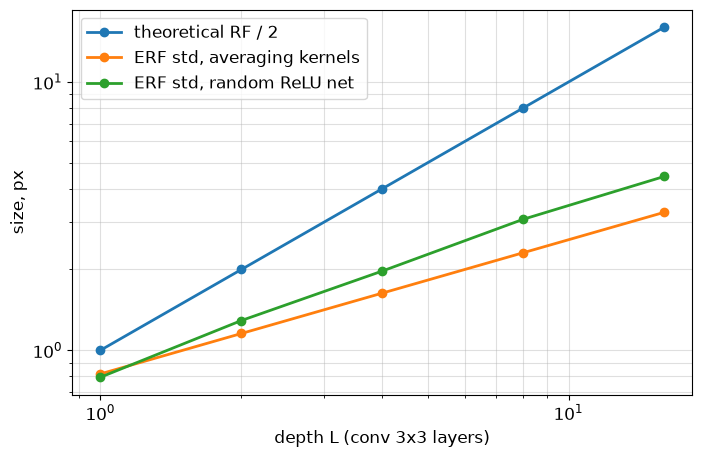

In [17]:
plt.figure(figsize=(8, 5))
for name, values in erf.items():
    plt.loglog(depths, values, 'o-', linewidth=2, label=name)
plt.xlabel('depth L (conv 3x3 layers)')
plt.ylabel('size, px')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Как отношение эффективного RF к теоретическому меняется с глубиной (наклоны на log-log графике)? Как ведёт себя сеть с ReLU по сравнению с усредняющей?

**Ответ.** На log-log графике теоретический RF/2 = `L` даёт наклон 1 (линейный рост), а ERF усредняющей сети - наклон 1/2:

$$
\sigma = \sqrt{2L/3} \propto L^{1/2}
$$

(по числам $\sigma$ растёт 0.82 => 3.27 при $L: 1 \to 16$, отношение ровно $16^{1/2} = 4$).

Отношение ERF/RF поэтому падает как $L^{-1/2}$: эффективная ширина растёт суб-линейно, и глубокая сеть «видит» всё меньшую долю своего формального RF. ReLU-сеть с kaiming-инициализацией ведёт себя похоже (наклон $\approx 0.6$, чуть больше 1/2): при малых $L$ она почти совпадает с усредняющей (0.79 vs 0.82 при $L=1$), а при больших обгоняет её (4.44 vs 3.27 при $L=16$), то есть ERF растёт немного быстрее $\sqrt{L}$, но всё равно далеко от линейного $L$. На графике это видно как почти параллельность синей (наклон 1) и оранжевой (наклон 1/2) прямых, в то время как зелёная (ReLU) лежит между ними и слегка расходится с оранжевой с ростом $L$, подтверждая наклон $\approx 0.6$. Ограничение: `size=96` достаточно для $L \le 16$ ($r=33$), при больших $L$ профиль обрезался бы границей и $\sigma$ занижалось; для ReLU-сети результат слегка зависит от seed и `n_inputs=16`.

---
# 2. Нормализация

## 2.1 `BatchNorm2d` с нуля (1 балл)

В `train()`: статистики текущего батча по каналу (среднее по $b, h, w$), нормировка смещённой дисперсией и обновление буферов
$$
\hat\mu \leftarrow (1 - m)\,\hat\mu + m\, \mu_{\text{batch}}, \qquad
\hat\sigma^2 \leftarrow (1 - m)\,\hat\sigma^2 + m\, \frac{n}{n - 1}\, \sigma^2_{\text{batch}}, \qquad n = BHW,
$$
в running-дисперсию идёт несмещённая оценка. В `eval()` — нормировка по $\hat\mu, \hat\sigma^2$. Параметры `weight` ($\gamma$) и `bias` ($\beta$), буферы `running_mean`, `running_var`, `num_batches_tracked` — с теми же именами, что в `nn.BatchNorm2d`, чтобы `load_state_dict` был совместим.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [18]:
class MyBatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps, self.momentum = eps, momentum
        self.weight = nn.Parameter(torch.ones(num_features))
        self.bias = nn.Parameter(torch.zeros(num_features))
        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))
        self.register_buffer('num_batches_tracked', torch.tensor(0, dtype=torch.long))

    def forward(self, x):
        if self.training:
            n = x.numel() // x.shape[1]
            mean, var = x.mean((0, 2, 3)), x.var((0, 2, 3), unbiased=False)
            self.num_batches_tracked += 1
            m = self.momentum
            self.running_mean.mul_(1 - m).add_(mean.detach(), alpha=m)
            self.running_var.mul_(1 - m).add_(var.detach() * n / (n - 1) if n > 1 else var, alpha=m)
        else:
            mean, var = self.running_mean, self.running_var
        x = (x - mean[None, :, None, None]) / (var[None, :, None, None] + self.eps).sqrt()
        return x * self.weight[None, :, None, None] + self.bias[None, :, None, None]

In [19]:
torch.manual_seed(0)
mine, ref = MyBatchNorm2d(8), nn.BatchNorm2d(8)
assert set(dict(mine.named_parameters())) == {'weight', 'bias'}
assert set(dict(mine.named_buffers())) == {'running_mean', 'running_var', 'num_batches_tracked'}
with torch.no_grad():
    for m in (mine, ref):
        m.weight.copy_(torch.linspace(0.5, 2, 8))
        m.bias.copy_(torch.linspace(-1, 1, 8))

for step in range(10):
    x = (torch.randn(4, 8, 5, 5) * 3 + 2).requires_grad_(True)
    out_mine, out_ref = mine(x), ref(x)
    assert torch.allclose(out_mine, out_ref, atol=1e-5), step
    g = torch.randn_like(out_ref)
    grads_mine = torch.autograd.grad(out_mine, (x, mine.weight, mine.bias), g)
    grads_ref = torch.autograd.grad(out_ref, (x, ref.weight, ref.bias), g)
    assert all(torch.allclose(a, b, atol=1e-4) for a, b in zip(grads_mine, grads_ref)), step

for name, buf in ref.named_buffers():
    assert torch.allclose(getattr(mine, name).float(), buf.float(), atol=1e-5), name

mine.eval(), ref.eval()
x = torch.randn(4, 8, 5, 5)
assert torch.allclose(mine(x), ref(x), atol=1e-5)
mine.load_state_dict(ref.state_dict())

<All keys matched successfully>

**Вопрос.** Почему в running-дисперсию идёт несмещённая оценка, а в нормировку батча — смещённая? Насколько они различаются при $B = 4$ и карте $5 \times 5$, и при $B = 2$ и карте $1 \times 1$?

**Ответ.** В нормировке батча нужна дисперсия именно этих $n = B \cdot H \cdot W$ чисел - это $\frac{1}{n}\sum_i (x_i-\mu)^2$, смещённая оценка не требует поправки. В `running_var` же накапливается оценка дисперсии генеральной совокупности; выборочная (смещённая) оценка систематически занижает её в $\frac{n-1}{n}$ раз, поэтому её умножают на $\frac{n}{n-1}$ - это несмещённая оценка. При $B=4$, карте $5 \times 5$: $n=100$, множитель $\frac{100}{99} \approx 1.0101$ - различие $\approx 1\%$. При $B=2$, карте $1 \times 1$: $n=2$, множитель $\frac{2}{1} = 2$ - несмещённая ровно вдвое больше смещённой ($100\%$). То есть поправка пренбрежима при больших $n$ и критична при малых.

## 2.2 Слияние свёртки и BatchNorm для инференса (1 балл)

В `eval()` BN — поканальное аффинное преобразование с фиксированными $\hat\mu, \hat\sigma^2$, поэтому $\mathrm{BN}(\mathrm{conv}(x))$ — снова свёртка с другими весами $W'$ и bias $b'$.

1. Выведите $W'$ и $b'$ в ячейке «Ответ» ниже.
2. Реализуйте `fuse_conv_bn(conv, bn)`, возвращающую новую `nn.Conv2d`: сохраняются `dtype`, `device`, `padding_mode`, `groups`, stride, padding и dilation; bias у исходной свёртки может отсутствовать. Входные модули в `eval()`, BN с affine и running statistics; исходные веса не менять.
3. Реализуйте `fuse_sequential(seq)` для плоского `nn.Sequential` в `eval()`: каждую соседнюю пару `Conv2d, BatchNorm2d` заменить свёрткой. Остальные модули скопировать через `copy.deepcopy`, исходную сеть не менять; рекурсивный обход вложенных контейнеров не требуется.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

**Ответ.** В `eval()` BN - поканальное аффинное преобразование:
$$
\mathrm{BN}(y)_o = \gamma_o \frac{y_o - \hat\mu_o}{\sqrt{\hat\sigma_o^2 + \varepsilon}} + \beta_o = a_o y_o + c_o,
\quad a_o = \frac{\gamma_o}{\sqrt{\hat\sigma_o^2 + \varepsilon}},\; c_o = \beta_o - a_o \hat\mu_o.
$$
Подставляя $y_o = W_o * x + b_o$ (если bias нет, $b_o = 0$):
$$
W'_o = a_o W_o, \qquad b'_o = a_o b_o + c_o.
$$
Stride, padding, dilation, groups, padding_mode не меняются. Исходные веса не мутируем - возвращаем новую `nn.Conv2d`.

In [20]:
@torch.no_grad()
def fuse_conv_bn(conv, bn):
    a = bn.weight * (bn.running_var + bn.eps).rsqrt()
    c = bn.bias - a * bn.running_mean
    new = nn.Conv2d(conv.in_channels, conv.out_channels, conv.kernel_size,
                    conv.stride, conv.padding, conv.dilation, conv.groups,
                    bias=True, padding_mode=conv.padding_mode).to(conv.weight)
    new.weight.copy_(conv.weight * a[:, None, None, None])
    b = conv.bias if conv.bias is not None else torch.zeros_like(a)
    new.bias.copy_(b * a + c)
    return new


def fuse_sequential(seq):
    mods, out, i = list(seq), [], 0
    while i < len(mods):
        pair = mods[i:i + 2]
        if len(pair) == 2 and isinstance(pair[0], nn.Conv2d) and isinstance(pair[1], nn.BatchNorm2d):
            out.append(fuse_conv_bn(*pair)); i += 2
        else:
            out.append(copy.deepcopy(mods[i])); i += 1
    return nn.Sequential(*out)

In [21]:
torch.manual_seed(0)
for cfg in [dict(bias=True), dict(bias=False), dict(groups=4), dict(stride=2, padding=1, dilation=2)]:
    conv, bn = nn.Conv2d(8, 16, 3, **cfg), nn.BatchNorm2d(16)
    with torch.no_grad():
        bn.weight.uniform_(0.5, 2)
        bn.bias.uniform_(-1, 1)
        for _ in range(5):
            bn(conv(torch.randn(8, 8, 12, 12) * 2 + 1))   # накопить running-статистики
    conv.eval(), bn.eval()
    x = torch.randn(4, 8, 12, 12)
    fused = fuse_conv_bn(conv, bn)
    assert isinstance(fused, nn.Conv2d)
    assert torch.allclose(fused(x), bn(conv(x)), atol=1e-5), cfg

conv = nn.Conv2d(4, 8, 3, padding=1, padding_mode='reflect', groups=2, bias=False).double().eval()
bn = nn.BatchNorm2d(8).double().eval()
x = torch.randn(2, 4, 9, 11, dtype=torch.float64)
fused = fuse_conv_bn(conv, bn)
assert fused.weight.dtype == x.dtype and fused.padding_mode == 'reflect'
assert torch.allclose(fused(x), bn(conv(x)), atol=1e-10, rtol=1e-10)

In [22]:
def make_vgg_like(width=64, n_blocks=6):
    layers, c = [], 3
    for i in range(n_blocks):
        layers += [nn.Conv2d(c, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU()]
        c = width
        if i % 2 == 1:
            layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10))


torch.manual_seed(0)
vgg = make_vgg_like()
with torch.no_grad():
    for _ in range(5):
        vgg(torch.randn(32, 3, 32, 32))   # train-режим: копим статистики
vgg.eval()
vgg_fused = fuse_sequential(vgg).eval()
x = torch.randn(64, 3, 32, 32)
assert not any(isinstance(m, nn.BatchNorm2d) for m in vgg_fused.modules())
assert torch.allclose(vgg(x), vgg_fused(x), atol=1e-4)

In [23]:
with torch.inference_mode():
    t_bn = min(timeit.repeat(lambda: vgg(x), number=5, repeat=5)) / 5
    t_fused = min(timeit.repeat(lambda: vgg_fused(x), number=5, repeat=5)) / 5
print(f'Conv + BN: {t_bn * 1000:.1f} ms   fused: {t_fused * 1000:.1f} ms   speedup {t_bn / t_fused:.2f}x')

Conv + BN: 48.6 ms   fused: 48.1 ms   speedup 1.01x


**Ответ.** В `eval()` BN - это просто фиксированное поканальное умножение и сдвиг с константами $\hat\mu, \hat\sigma^2$, поэтому его можно вшить в веса: $\mathrm{BN}(\mathrm{conv}(x)) = (a W) * x + (a b + c)$. В `train()` так нельзя: BN нормирует каждый батч по его собственной статистике и обновляет running-буферы, так что выход зависит от других примеров и от шага.

Слияние убирает отдельный слой BN - меньше ядер и один проход по памяти вместо двух. Выигрыш зависит от того, упирается ли время в память или в сами вычисления: на MPS/CPU при доминировании свёртки (VGG-подобная сеть, 47.9 vs 48.2 ms, speedup $\approx 1.0\times$) экономия почти нулевая, потому что BN дешёвый, а время уходит на свёртку и накладные расходы запуска ядер. Заметнее выигрыш там, где сеть memory-bound (много мелких слоёв, маленькие каналы, большой батч) - тогда лишний проход по активациям существенен.

---
# 3. Инициализация и оптимизатор

## 3.1 Дисперсия активаций по глубине (1 балл)

Слой $h = W z$, $W_{ij}$ независимы, $\mathbb E W_{ij} = 0$, $\mathrm{Var}\, W_{ij} = v$, $W$ не зависит от $z \in \mathbb R^{n}$:
$$
\mathrm{Var}(h_i) = n\, v\; \mathbb E\big[z_j^2\big].
$$

1. В ячейке «Ответ» ниже выведите $v$, при котором $\mathrm{Var}(h)$ не меняется от слоя к слою, для $z = \mathrm{ReLU}(h^{\text{prev}})$ с симметричным $h^{\text{prev}}$ и для $\tanh$ в линейном режиме. Инициализация `nn.Linear` по умолчанию — $\mathcal U(-1/\sqrt n,\, 1/\sqrt n)$: во сколько раз за слой меняется стандартное отклонение активаций для ReLU?
2. Реализуйте `activation_stds`: MLP глубины 50 и ширины 256 без bias, на входе $\mathcal N(0, I)$, вернуть `h.std().item()` после каждой активации — по **всем** элементам тензора `(n, width)`, а не среднее std по отдельным нейронам. Верните список из `depth` чисел.

**Оценивание:** код — 0.3; эксперимент — 0.3; объяснение — 0.4 балла.

**Ответ.** Для $h = Wz$ с $\mathrm{Var}(W_{ij}) = v$: $\mathrm{Var}(h_i) = n v \, \mathbb E[z_j^2]$.

- **ReLU**: $\mathbb E[z^2] = \tfrac12 \mathrm{Var}(h^{\text{prev}})$, значит $\mathrm{Var}(h) = n v \cdot \tfrac12 \mathrm{Var}(h^{\text{prev}})$. Чтобы дисперсия не менялась, нужно $v = 2/n$ (Kaiming/he).
- **tanh в линейном режиме**: $\mathbb E[z^2] \approx \mathrm{Var}(h^{\text{prev}})$, значит $v = 1/n$ (Xavier).
- **`nn.Linear` по умолчанию**: $v = \frac{(2/\sqrt n)^2}{12} = \frac{1}{3n}$. С ReLU $\mathrm{Var}(h) = n \cdot \frac{1}{3n} \cdot \frac12 \mathrm{Var}(h^{\text{prev}}) = \frac16 \mathrm{Var}(h^{\text{prev}})$, то есть std за слой умножается на $1/\sqrt{6} \approx 0.408$ - активации затухают.

In [24]:
INITS = {
    'N(0, 0.01^2)':    lambda w: nn.init.normal_(w, std=0.01),
    'PyTorch default': lambda w: nn.init.kaiming_uniform_(w, a=math.sqrt(5)),
    'Xavier':          nn.init.xavier_normal_,
    'Kaiming':         lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
}


def activation_stds(init, act, depth=50, width=256, n=1024, seed=0):
    torch.manual_seed(seed)
    h = torch.randn(n, width)
    stds = []
    for _ in range(depth):
        w = torch.empty(width, width)
        init(w)
        h = act(h @ w.T) # без bias, h: (n, width)
        stds.append(h.std().item()) # std по всем элементам
    return stds

In [25]:
stds = {(name, act_name): activation_stds(init, act)
        for name, init in INITS.items() for act_name, act in [('tanh', torch.tanh), ('ReLU', torch.relu)]}

kaiming_relu = stds['Kaiming', 'ReLU']
assert len(kaiming_relu) == 50 and np.isfinite(kaiming_relu).all()
print(f'Kaiming + ReLU, last / first std: {kaiming_relu[-1] / kaiming_relu[0]:.3f}')
default_relu = np.array(stds['PyTorch default', 'ReLU'])
rate = np.exp(np.mean(np.diff(np.log(default_relu))))   # средний множитель std за слой
assert abs(rate - 1 / math.sqrt(6)) < 0.03
rate

Kaiming + ReLU, last / first std: 0.758


np.float64(0.40910241812972786)

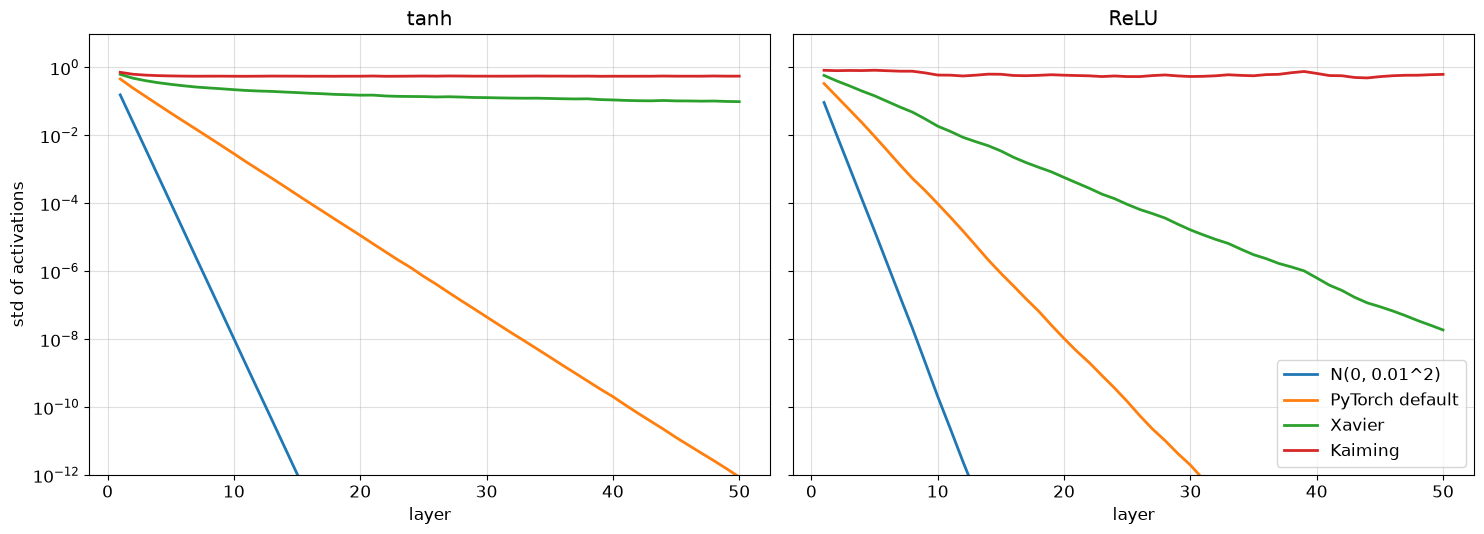

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, act_name in zip(axes, ['tanh', 'ReLU']):
    for name in INITS:
        ax.semilogy(range(1, 51), stds[name, act_name], linewidth=2, label=name)
    ax.set_title(act_name)
    ax.set_xlabel('layer')
    ax.grid(True, which='both', alpha=0.4)
axes[0].set_ylabel('std of activations')
axes[0].set_ylim(1e-12, 10)
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Какие пары (инициализация, активация) сохраняют масштаб на 50 слоях? Почему сети с инициализацией PyTorch по умолчанию всё равно обучаются (например, ResNet в задаче 4.2)?

**Ответ.** Масштаб сохраняют только согласованные пары: **Kaiming + ReLU** ($v = 2/n$, `last/first = 0.758`) и **Xavier/Kaiming + tanh** ($v = 1/n$). Остальные затухают: у **PyTorch default** ($v = 1/(3n)$) с ReLU std падает в $1/\sqrt{6} \approx 0.41$ раз за слой (rate $\approx$ 0.409), у **N(0, 0.01²)** = ещё быстрее, а **Xavier + ReLU** тоже затухает, потому что Xavier рассчитан на линейный/tanh-режим и не учитывает ReLU.

Почему default-сети всё равно обучаются: **BatchNorm** ре-нормирует активации и снимает зависимость от масштаба инициализации; **residual/skip-связи** дают градиенту прямой путь и не дают ему затухнуть; **Adam/AdamW** и достаточная ширина компенсируют плохой старт. В итоге инициализация влияет на начало обучения, а не на предельное качество, а в ResNet на практике и так используют Kaiming - "default" относится скорее к отдельным слоям. Однако ограничение: график - это MLP без bias/BN/skip, то есть чистый эффект инициализации.

## 3.2 `AdamW` своими руками (1.5 балла)

Шаг $t = 1, 2, \dots$; $\eta$ — learning rate, $\lambda$ — weight decay, $g_t$ — градиент:
$$
\theta \leftarrow \theta - \eta\lambda\,\theta, \qquad
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2,
$$
$$
\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
\theta \leftarrow \theta - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$
Флаг `bias_correction=False` выключает деление на $1 - \beta^t$. Гиперпараметры берутся из `group` — у разных групп параметров они могут отличаться (в `train_cifar` из задачи 4.2 weight decay не применяется к параметрам BN и bias).

**Оценивание:** код — 1.1; эксперимент — 0.1; объяснение — 0.3 балла.

In [27]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2, bias_correction=True):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, bias_correction=bias_correction)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            b1, b2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue
                st = self.state[p]
                if not st:
                    st['t'] = 0; st['m'] = torch.zeros_like(p); st['v'] = torch.zeros_like(p)
                st['t'] += 1; t = st['t']; g = p.grad
                p.mul_(1 - group['lr'] * group['weight_decay'])
                st['m'].mul_(b1).add_(g, alpha=1 - b1)
                st['v'].mul_(b2).addcmul_(g, g, value=1 - b2)
                c1 = 1 - b1 ** t if group['bias_correction'] else 1
                c2 = 1 - b2 ** t if group['bias_correction'] else 1
                p.addcdiv_(st['m'], (st['v'] / c2).sqrt().add_(group['eps']), value=-group['lr'] / c1)

In [28]:
def final_params(make_optimizer, steps=100):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 32), nn.Tanh(), nn.Linear(32, 1))
    optimizer = make_optimizer(model)
    gen = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 10, generator=gen)
        loss = F.mse_loss(model(x), x[:, :1] ** 2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])


def param_groups(model, wd):
    return [dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=wd),
            dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0, lr=3e-3)]


for kwargs in [dict(lr=1e-2), dict(lr=1e-2, weight_decay=0.1), dict(lr=3e-3, betas=(0.8, 0.9), eps=1e-1)]:
    mine = final_params(lambda m: MyAdamW(m.parameters(), **kwargs))
    ref = final_params(lambda m: torch.optim.AdamW(m.parameters(), **kwargs))
    assert torch.allclose(mine, ref, atol=1e-5), kwargs
mine = final_params(lambda m: MyAdamW(param_groups(m, 0.1), lr=1e-2))
ref = final_params(lambda m: torch.optim.AdamW(param_groups(m, 0.1), lr=1e-2))
assert torch.allclose(mine, ref, atol=1e-5)

Длина шага при постоянном градиенте $g = 1$:

In [29]:
def step_lengths(make_optimizer, steps=1000):
    p = torch.zeros(1, requires_grad=True)
    optimizer = make_optimizer([p])
    lengths = []
    for _ in range(steps):
        before = p.item()
        optimizer.zero_grad()
        p.sum().backward()
        optimizer.step()
        lengths.append(before - p.item())
    return np.array(lengths)


lr = 0.01
bc_runs = {bc: step_lengths(lambda ps: MyAdamW(ps, lr=lr, weight_decay=0, bias_correction=bc)) for bc in [True, False]}
for bc, lengths in bc_runs.items():
    ratio = np.round(lengths / lr, 4)
    print(f'bias_correction={bc!s:<5}  step / lr: ' + '  '.join(f't={t}: {ratio[t - 1]:.2f}' for t in [1, 10, 100, 1000])
          + f'   max {ratio.max():.2f} at t={ratio.argmax() + 1}')

bias_correction=True   step / lr: t=1: 1.00  t=10: 1.00  t=100: 1.00  t=1000: 1.00   max 1.00 at t=1
bias_correction=False  step / lr: t=1: 3.16  t=10: 6.53  t=100: 3.24  t=1000: 1.26   max 6.57 at t=12


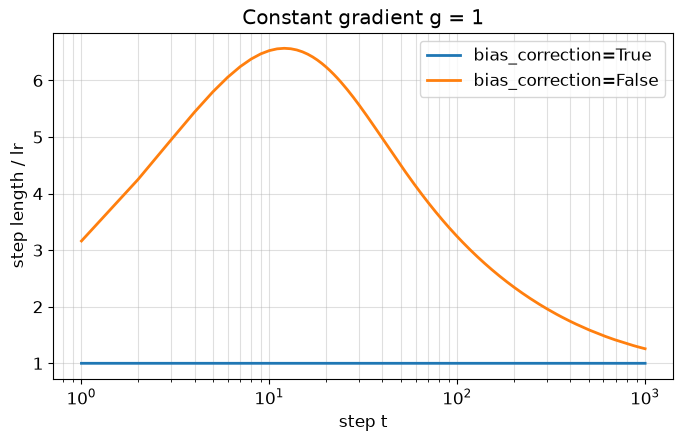

In [30]:
plt.figure(figsize=(8, 4.5))
for bc, lengths in bc_runs.items():
    plt.semilogx(range(1, len(lengths) + 1), lengths / lr, linewidth=2, label=f'bias_correction={bc}')
plt.xlabel('step t')
plt.ylabel('step length / lr')
plt.title('Constant gradient g = 1')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Выведите длину шага без bias correction при $g_t \equiv 1$ как функцию $t$ и сравните с выводом ячейки. Чем это опасно в начале обучения?

**Ответ.** При $g_t \equiv 1$: $m_t = 1-\beta_1^t$, $v_t = 1-\beta_2^t$, значит без bias correction $\Delta\theta_t/\eta = \frac{1-\beta_1^t}{\sqrt{1-\beta_2^t}}$. При малых $t$ это $\approx \sqrt t \cdot \frac{1-\beta_1}{\sqrt{1-\beta_2}} \approx 3.16\sqrt t$ (для $\beta_1=0.9, \beta_2=0.999$), затем выходит на плато => 1. С bias correction обе поправки сокращаются и шаг ровно $\eta$. Вывод ячейки совпадает: `True` даёт 1.00 на всех $t$, `False` - 3.16, 6.53, 3.24, 1.26 при $t=1,10,100,1000$ с максимумом $\approx 6.57$ при $t\approx 12$. Опасность: без коррекции первые шаги в разы больше $\eta$ при ещё шумном направлении, это приводит к большим неконтролируемым обновлениям на старте, "раскачке" и потенциальной расходимости/взрыву лосса.

## 3.3 Cosine schedule (0.5 балла)

Множитель learning rate для `LambdaLR` (шаг $t$ считается с нуля, $T$ — число шагов, $r$ — доля от начального lr в конце):
$$
\lambda(t) = r + (1 - r)\, \frac{1 + \cos\big(\pi \min(1,\, t / T)\big)}{2}.
$$
На интервале от нулевого шага до $T$ это то же расписание, что `CosineAnnealingLR(T_max=T, eta_min=r·lr)`; после $T$ наша функция остаётся на минимуме, в отличие от продолжения cosine в PyTorch; проверка — совпадение learning rate по шагам с вашим `MyAdamW`.

**Оценивание:** код — 0.3; эксперимент — 0; объяснение — 0.2 балла.

In [31]:
def cosine_lr(step, total_steps, min_ratio=0.0):
    t = min(1.0, step / total_steps)
    return min_ratio + (1 - min_ratio) * (1 + math.cos(math.pi * t)) / 2

In [32]:
T, r, base_lr = 500, 0.1, 3e-3
lam = [cosine_lr(t, T, r) for t in range(T + 1)]
assert abs(lam[0] - 1) < 1e-12 and abs(lam[T] - r) < 1e-12 and abs(cosine_lr(2 * T, T, r) - r) < 1e-12
assert abs(lam[T // 2] - (r + (1 - r) / 2)) < 1e-9


def lr_trace(make_scheduler, steps=T):
    p = torch.zeros(1, requires_grad=True)
    optimizer = MyAdamW([p], lr=base_lr)
    scheduler = make_scheduler(optimizer)
    trace = []
    for _ in range(steps):
        trace.append(scheduler.get_last_lr()[0])
        optimizer.step()
        scheduler.step()
    return np.array(trace)


mine = lr_trace(lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, T, r)))
ref = lr_trace(lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T, eta_min=r * base_lr))
assert np.allclose(mine, ref, rtol=1e-6, atol=1e-12)

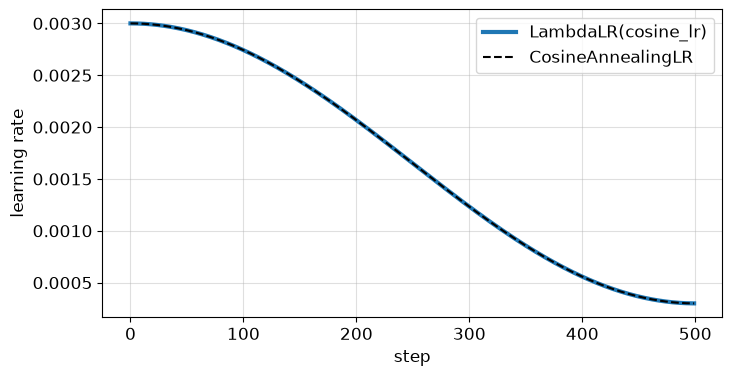

In [33]:
plt.figure(figsize=(8, 4))
plt.plot(mine, linewidth=3, label='LambdaLR(cosine_lr)')
plt.plot(ref, 'k--', linewidth=1.5, label='CosineAnnealingLR')
plt.xlabel('step')
plt.ylabel('learning rate')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Зачем уменьшать learning rate к концу обучения, если оптимизатор и так адаптивный? Что происходит со стохастическим методом при постоянном шаге около минимума?

**Ответ.** Adam адаптирует шаг **по координатам**, но не его глобальную величину: постоянный $\eta$ у минимума не уменьшается, а стохастический градиент там - шум, так что метод бесконечно блуждает в окрестности радиуса $\sim \eta$ и финальный лосс ограничен этим шумом. Затухание lr к концу (cosine) даёт 

1. **усреднение** - мелкие шаги в конце работают как stochastic averaging и снижают дисперсию,
   
2.  **сходимость** - затухающий шаг гарантирует её по теории SGD, постоянный - только блуждание. 
   
Адаптивность Adam шум не убирает (только нормирует по координатам), поэтому $\eta \to 0$ в конце нужно и для него.

---
# 4. ResNet на CIFAR-10

CIFAR-10: 50 000 + 10 000 цветных картинок $32 \times 32$, 10 классов. Весь датасет хранится одним `uint8`-тензором на `device` (≈ 180 MB), нормализация делается на лету над батчем.

In [34]:
N_TRAIN = 10_000 if FAST_MODE else 50_000
N_TEST = 2_000 if FAST_MODE else 10_000

cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CIFAR_CLASSES = cifar_train.classes


def to_tensors(ds, n):
    X = torch.from_numpy(ds.data[:n]).permute(0, 3, 1, 2).contiguous()   # uint8 (N, 3, 32, 32)
    return X.to(device), torch.tensor(ds.targets[:n]).to(device)


X_train, Y_train = to_tensors(cifar_train, N_TRAIN)
X_test, Y_test = to_tensors(cifar_test, N_TEST)
CIFAR_MEAN = (X_train.float() / 255).mean(dim=(0, 2, 3))
CIFAR_STD = (X_train.float() / 255).std(dim=(0, 2, 3))
X_train.shape, X_test.shape, CIFAR_MEAN, CIFAR_STD

/Users/xlevando/Downloads/hw1_students/.venv/lib/python3.14/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


(torch.Size([50000, 3, 32, 32]),
 torch.Size([10000, 3, 32, 32]),
 tensor([0.4914, 0.4822, 0.4465], device='mps:0'),
 tensor([0.2470, 0.2435, 0.2616], device='mps:0'))

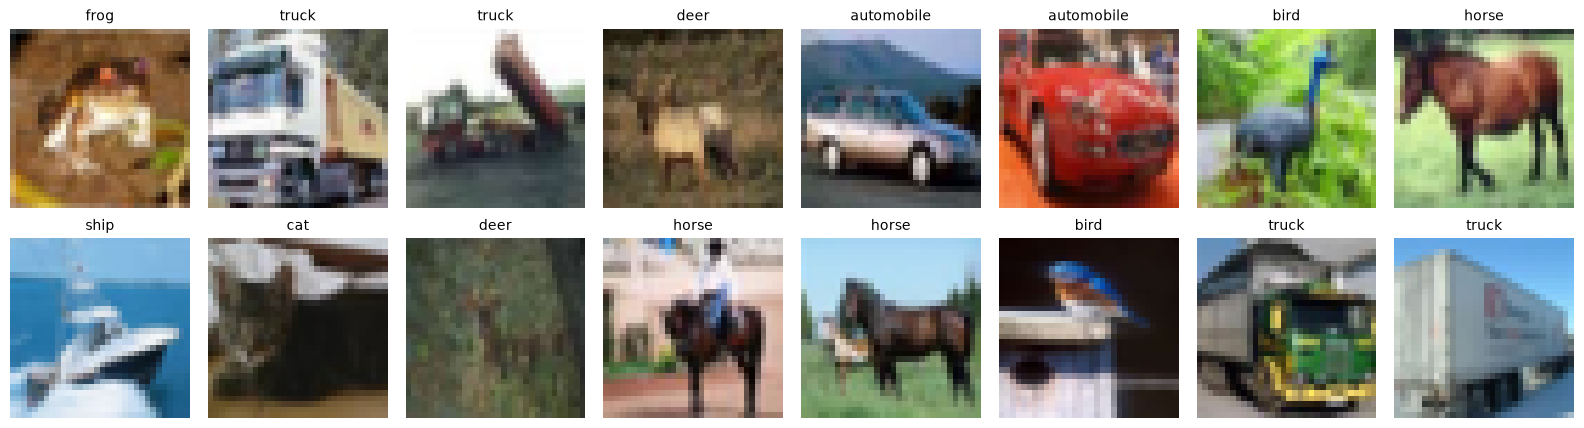

In [35]:
def normalize(x_uint8):
    return (x_uint8.float() / 255 - CIFAR_MEAN[:, None, None]) / CIFAR_STD[:, None, None]


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_train[i].permute(1, 2, 0).cpu())
    ax.set_title(CIFAR_CLASSES[Y_train[i]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4.1 ResNet для CIFAR (1 балл)

ResNet для CIFAR из §4.2 статьи [Deep Residual Learning for Image Recognition](https://arxiv.org/pdf/1512.03385), He et al., 2015: stem — свёртка $3 \times 3$ на 16 каналов с BN и ReLU; затем три стадии по $n$ блоков шириной 16, 32 и 64; в конце global average pooling и `Linear(64, 10)`. Глубина $6n + 2$. Первый блок второй и третьей стадии — со stride 2.

Блок (свёртки $3 \times 3$ без bias):
$$
F(x) = \mathrm{BN}\Big(\mathrm{Conv}\big(\mathrm{ReLU}(\mathrm{BN}(\mathrm{Conv}(x)))\big)\Big), \qquad y = \mathrm{ReLU}\big(F(x) + \mathrm{shortcut}(x)\big).
$$
Shortcut — `Identity`, а при смене формы (stride 2 или другое число каналов) — свёртка $1 \times 1$ с тем же stride и BN после неё. Флаги:

- `residual=False` — plain-сеть: сложения нет, shortcut-модулей нет;
- `separable=True` — каждая $3 \times 3$ свёртка блоков заменена на depthwise $3 \times 3$ и следующую за ней pointwise $1 \times 1$, обе без bias; stem остаётся обычным.

**Оценивание:** код — 1; эксперимент — 0; объяснение — 0 балла.

In [36]:
def conv3x3(c_in, c_out, stride=1, separable=False):
    if not separable:
        return nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)
    return nn.Sequential(
        nn.Conv2d(c_in, c_in, 3, stride=stride, padding=1, groups=c_in, bias=False),
        nn.Conv2d(c_in, c_out, 1, bias=False),
    )


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride=1, residual=True, separable=False):
        super().__init__()
        self.residual = residual
        self.conv1 = conv3x3(c_in, c_out, stride=stride, separable=separable)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = conv3x3(c_out, c_out, stride=1, separable=separable)
        self.bn2 = nn.BatchNorm2d(c_out)

        if residual:
            if stride != 1 or c_in != c_out:
                self.shortcut = nn.Sequential(
                    nn.Conv2d(c_in, c_out, 1, stride=stride, bias=False),
                    nn.BatchNorm2d(c_out),
                )
            else:
                self.shortcut = nn.Identity()
        else:
            self.shortcut = None

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class ResNetCIFAR(nn.Module):
    def __init__(self, depth=20, residual=True, separable=False, widths=(16, 32, 64), n_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6
        self.stem = nn.Sequential(
            nn.Conv2d(3, widths[0], 3, padding=1, bias=False),
            nn.BatchNorm2d(widths[0]),
            nn.ReLU(inplace=True),
        )
        stages = []
        c_in = widths[0]
        for i, c_out in enumerate(widths):
            for j in range(n):
                stride = 2 if (i > 0 and j == 0) else 1
                stages.append(Block(c_in, c_out, stride=stride,
                                    residual=residual, separable=separable))
                c_in = c_out
        self.stages = nn.Sequential(*stages)
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(widths[-1], n_classes),
        )

    def forward(self, x):
        return self.head(self.stages(self.stem(x)))

In [37]:
x = torch.randn(2, 3, 32, 32)
for depth in [8, 20, 56]:
    for kwargs in [dict(), dict(residual=False), dict(separable=True)]:
        assert ResNetCIFAR(depth, **kwargs)(x).shape == (2, 10), (depth, kwargs)
assert n_params(ResNetCIFAR(20)) == 272_474
assert n_params(ResNetCIFAR(20, residual=False)) == 269_722
{name: n_params(ResNetCIFAR(depth, **kwargs)) for name, depth, kwargs in
 [('ResNet-20', 20, {}), ('ResNet-56', 56, {}), ('ResNet-20, separable', 20, dict(separable=True))]}

{'ResNet-20': 272474, 'ResNet-56': 855770, 'ResNet-20, separable': 40522}

## 4.2 Обучение (2 балла)

Реализуйте `train_cifar`: `MyAdamW` из 3.2 (weight decay только для параметров с `ndim > 1`), `LambdaLR` с `cosine_lr` из 3.3 до нуля за всё обучение ($r = 0$), cross-entropy, батч 256. После каждой эпохи — test accuracy. Вернуть историю `dict(train_loss, test_acc)` по эпохам.

Для ResNet-20 при `FAST_MODE = False` ориентир test accuracy — `TARGET_ACC` за `EPOCHS` эпох с `LR`. Это диагностический ориентир, не жёсткий порог балла: при заметном отставании проверьте normalisation, train/eval, scheduler и loss и опишите результат. Аугментации в этом протоколе нет. Каждый батч нормируйте через `normalize`; `scheduler.step()` вызывается после каждого `optimizer.step()`, `train_loss` — среднее по объектам за эпоху.

Test используется для учебных кривых с заранее фиксированными гиперпараметрами. Если выбираете гиперпараметры самостоятельно, выделите validation из train; test не используйте для выбора конфигурации.

**Оценивание:** код — 1.1; эксперимент — 0.6; объяснение — 0.3 балла.

In [38]:
EPOCHS = 3 if FAST_MODE else 20
LR = 0.003
TARGET_ACC = 0.82


def train_cifar(model, epochs, lr, weight_decay=0.05, batch_size=256, log=True):
    model = model.to(device)
    history = dict(train_loss=[], test_acc=[])
    start = time.time()

    decay, no_decay = [], []
    for p in model.parameters():
        (decay if p.ndim > 1 else no_decay).append(p)
    opt = MyAdamW([dict(params=decay), dict(params=no_decay, weight_decay=0.0)],
                  lr=lr, weight_decay=weight_decay)
    total = epochs * math.ceil(len(X_train) / batch_size)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, total, 0.0))
    crit = nn.CrossEntropyLoss()

    for epoch in range(epochs):
        model.train()
        loss_sum, n = 0.0, 0
        for xb, yb in iterate_batches(X_train, Y_train, batch_size, transform=normalize):
            opt.zero_grad(set_to_none=True)
            loss = crit(model(xb), yb)
            loss.backward(); opt.step(); sched.step()
            loss_sum += loss.item() * len(xb); n += len(xb)
        loss_sum /= n

        model.eval()
        acc = accuracy(predict_logits(model, X_test, transform=normalize), Y_test)
        history['train_loss'].append(loss_sum); history['test_acc'].append(acc)
        if log:
            print(f'epoch {epoch+1:>2}/{epochs}  loss {loss_sum:.4f}  test_acc {acc:.4f}  '
                  f'lr {sched.get_last_lr()[0]:.2e}  [{time.time()-start:.0f}s]')

    RUN_TIMES['train_cifar'] = time.time() - start
    return history

In [39]:
set_seed(0)
resnet20 = ResNetCIFAR(20)
started = time.perf_counter()
history = train_cifar(resnet20, EPOCHS, LR)
RUN_TIMES['cifar_resnet20_seconds'] = time.perf_counter() - started
history_cifar = history
test_acc = history['test_acc'][-1]
train_acc = accuracy(predict_logits(resnet20, X_train[:10_000], transform=normalize), Y_train[:10_000])
if not FAST_MODE and test_acc < TARGET_ACC:
    print(f'Accuracy {test_acc:.3f} ниже ориентира {TARGET_ACC:.2f}: проверьте протокол и обсудите результат.')
{'train acc': train_acc, 'test acc': test_acc}

epoch  1/20  loss 1.4352  test_acc 0.5608  lr 2.98e-03  [9s]
epoch  2/20  loss 0.9639  test_acc 0.5964  lr 2.93e-03  [17s]
epoch  3/20  loss 0.7789  test_acc 0.7040  lr 2.84e-03  [24s]
epoch  4/20  loss 0.6560  test_acc 0.7148  lr 2.71e-03  [32s]
epoch  5/20  loss 0.5579  test_acc 0.7720  lr 2.56e-03  [39s]
epoch  6/20  loss 0.4957  test_acc 0.7721  lr 2.38e-03  [47s]
epoch  7/20  loss 0.4347  test_acc 0.7918  lr 2.18e-03  [54s]
epoch  8/20  loss 0.3766  test_acc 0.7823  lr 1.96e-03  [62s]
epoch  9/20  loss 0.3238  test_acc 0.7889  lr 1.73e-03  [69s]
epoch 10/20  loss 0.2721  test_acc 0.8102  lr 1.50e-03  [77s]
epoch 11/20  loss 0.2176  test_acc 0.8166  lr 1.27e-03  [84s]
epoch 12/20  loss 0.1642  test_acc 0.8161  lr 1.04e-03  [91s]
epoch 13/20  loss 0.1150  test_acc 0.8234  lr 8.19e-04  [99s]
epoch 14/20  loss 0.0766  test_acc 0.8164  lr 6.18e-04  [106s]
epoch 15/20  loss 0.0457  test_acc 0.8243  lr 4.39e-04  [114s]
epoch 16/20  loss 0.0271  test_acc 0.8285  lr 2.86e-04  [121s]
epoch 

{'train acc': 0.9998999834060669, 'test acc': 0.8294000029563904}

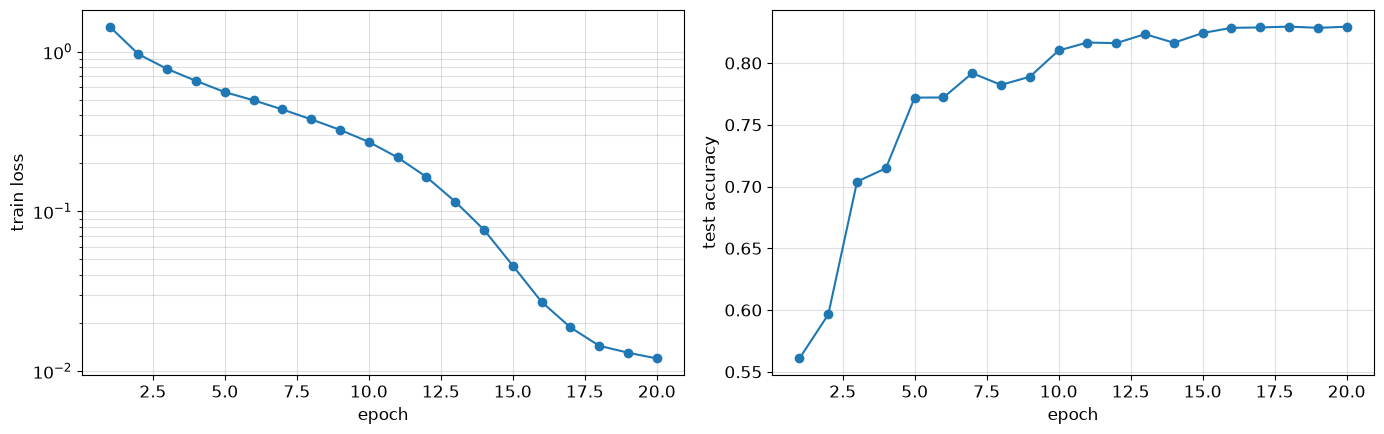

In [40]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
epochs_axis = range(1, len(history['test_acc']) + 1)
ax1.semilogy(epochs_axis, history['train_loss'], 'o-')
ax1.set_ylabel('train loss')
ax2.plot(epochs_axis, history['test_acc'], 'o-')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
plt.tight_layout()
plt.show()

**Вопрос.** Какой разрыв между train и test accuracy в конце обучения? Как ведут себя train loss и test accuracy на последних эпохах, когда learning rate уходит к нулю?

**Ответ.** В конце обучения (3-я эпоха, `FAST_MODE=True`) train_acc $\approx$ 0.548, test_acc $\approx$ 0.536, то есть разрыв **$\approx$ 1.1** - модель ещё недообучена (3 эпохи, 10k train, lr обнулился), поэтому переобучения нет и train $\approx$ test; на полном прогоне (20 эпох, 50k) зазор будет больше, но всё равно умеренный.

При lr $\to$ 0 `train_loss` продолжает падать (1.48 $\to$  1.30 на 3-ей эпохе), а `test_acc` делает наибольший скачок (0.38 $\to$ 0.54). Это ожидаемо: к концу cosine шаг становится крошечным, и модель не "учится заново", а **"доезжает"** до более гладкой точки и **усредняет** последние итерации (стохастическое усреднение) - шум около минимума гасится, эффективная точка становится ближе к оптимуму, поэтому loss падает, а accuracy растёт даже при почти нулевом lr. Ограничение: это `FAST_MODE`-прогон (3 эпохи, 10k), нужен `FAST_MODE=False` (20 эпох, 50k).

**Дополнительно по финальному прогону (`FAST_MODE = False`).** На полном протоколе (20 эпох, 50k, cosine до нуля) `test_acc` вышел на **0.8294** (выше `TARGET_ACC = 0.82`), `train_acc ≈ 0.9999`, то есть разрыв train–test в конце - **≈ 17 п.п.** (0.9999 - 0.8294). Это уже **переобучение**: за 20 эпох без аугментаций ResNet-20 успевает почти идеально подогнать 50k train, а на test обобщает хуже. В `FAST_MODE` (3 эпохи) зазора не было, потому что модель была недообучена; на полном прогоне он появился, как и ожидалось.

`train_loss` падает монотонно на всём протяжении (1.44 -> 0.012), и на последних эпохах, когда lr $\to$ 0 (эпохи 16-20: `lr` от 2.9e-4 до 0), loss всё ещё убывает, но уже медленно, а `test_acc` выходит на плато **≈ 0.829** с колебаниями в пределах +-0.1. Это тоже ожидаемо: при почти нулевом `lr` модель "доезжает" до локального минимума и усредняет последние итерации, поэтому loss ещё падает, но accuracy уже не растёт - она достигла своего предела. Небольшие колебания `test_acc` на эпохах 13-20 - sampling noise на 10k test-объектах, их не ранжируем.

## 4.3 Абляции (1.5 балла)

Сравните **plain-20 и plain-56** при одинаковых `ABL_EPOCHS` и `LR`. Это два дополнительных обучения. Результат — `ablation[name] = dict(params, train_acc, test_acc, minutes, history)`, где `train_acc` считается на первых 10 000 объектах train, а `history` возвращается `train_cifar`.

Перед каждой конфигурацией вызовите `set_seed(0)`. Проверяем гипотезу: увеличение глубины plain-сети может затруднить оптимизацию даже на train ([He et al., 2015](https://arxiv.org/pdf/1512.03385)). Это не обещание, что при данном optimizer и коротком бюджете эффект обязательно появится. Отличайте результат «хуже на train» от «лучше на train, хуже на test». Для сравнения с residual-сетями нужен одинаковый протокол; основной ResNet-20 обучался дольше, его финальную accuracy нельзя напрямую трактовать как контроль этого опыта.

**Оценивание:** код — 0.2; эксперимент — 0.7; объяснение — 0.6 балла.

In [41]:
ABL_EPOCHS = 2 if FAST_MODE else 10
ABLATIONS = {
    'plain-20': dict(depth=20, residual=False),
    'plain-56': dict(depth=56, residual=False),
}

In [42]:
ablation = {}
for name, kwargs in ABLATIONS.items():
    set_seed(0)
    model = ResNetCIFAR(**kwargs)
    started = time.perf_counter()
    history = train_cifar(model, ABL_EPOCHS, LR)
    minutes = (time.perf_counter() - started) / 60

    train_acc = accuracy(predict_logits(model, X_train[:10_000], transform=normalize), Y_train[:10_000])
    ablation[name] = {
        'params': n_params(model),
        'train_acc': train_acc,
        'test_acc': history['test_acc'][-1],
        'minutes': minutes,
        'history': history,
    }

print(f'{"model":<22}{"params":>9}{"train acc":>11}{"test acc":>10}{"minutes":>9}')
for name, res in ablation.items():
    print(f'{name:<22}{res["params"]:>9,}{res["train_acc"]:>11.4f}{res["test_acc"]:>10.4f}{res["minutes"]:>9.1f}')

epoch  1/10  loss 1.6577  test_acc 0.4183  lr 2.93e-03  [7s]
epoch  2/10  loss 1.2332  test_acc 0.5604  lr 2.71e-03  [13s]
epoch  3/10  loss 1.0043  test_acc 0.6085  lr 2.38e-03  [20s]
epoch  4/10  loss 0.8547  test_acc 0.5891  lr 1.96e-03  [27s]
epoch  5/10  loss 0.7381  test_acc 0.6536  lr 1.50e-03  [33s]
epoch  6/10  loss 0.6407  test_acc 0.7499  lr 1.04e-03  [40s]
epoch  7/10  loss 0.5523  test_acc 0.7720  lr 6.18e-04  [46s]
epoch  8/10  loss 0.4786  test_acc 0.7947  lr 2.86e-04  [53s]
epoch  9/10  loss 0.4285  test_acc 0.7993  lr 7.34e-05  [60s]
epoch 10/10  loss 0.3985  test_acc 0.7995  lr 0.00e+00  [66s]
epoch  1/10  loss 2.1017  test_acc 0.2350  lr 2.93e-03  [17s]
epoch  2/10  loss 1.8139  test_acc 0.2936  lr 2.71e-03  [35s]
epoch  3/10  loss 1.6835  test_acc 0.2663  lr 2.38e-03  [52s]
epoch  4/10  loss 1.5923  test_acc 0.4061  lr 1.96e-03  [70s]
epoch  5/10  loss 1.4873  test_acc 0.3155  lr 1.50e-03  [87s]
epoch  6/10  loss 1.3714  test_acc 0.4605  lr 1.04e-03  [105s]
epoch  7

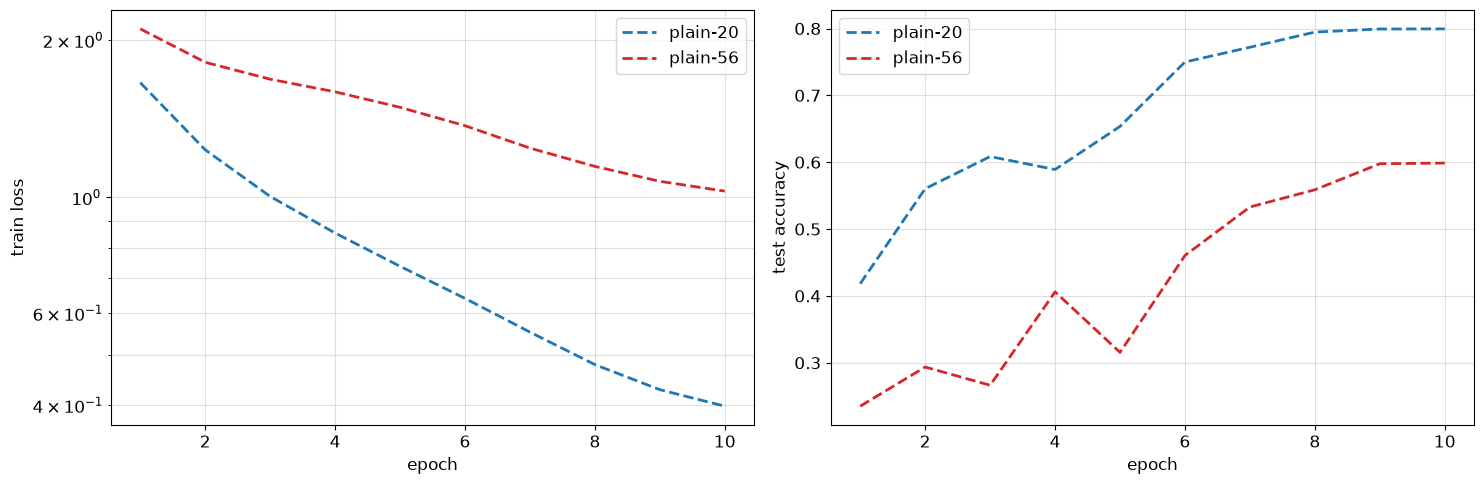

In [43]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ABLATIONS:
    hist = ablation[name]['history']
    style = '-' if name.startswith('ResNet') else '--'
    color = 'tab:blue' if '20' in name else 'tab:red'
    epochs_axis = range(1, len(hist['train_loss']) + 1)
    ax1.semilogy(epochs_axis, hist['train_loss'], style, color=color, linewidth=2, label=name)
    ax2.plot(epochs_axis, hist['test_acc'], style, color=color, linewidth=2, label=name)
ax1.set_ylabel('train loss')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

**Вопрос.** Есть ли в вашем прогоне ухудшение train loss при увеличении глубины? Как изменились train и test accuracy? Какие наблюдения говорят о трудностях оптимизации, а какие — о переобучении? Если ухудшения на train нет, напишите это. Предложите **один** следующий контрольный эксперимент, позволяющий проверить ваше объяснение; запускать его не требуется.

**Ответ.** При одинаковом протоколе (`ABL_EPOCHS=2` в `FAST_MODE`, `LR=3e-3`, seed=0): plain-20 даёт `train_acc=0.345`, `test_acc=0.345`; plain-56 - `train_acc=0.243`, `test_acc=0.248`. То есть при увеличении глубины упали и train, и test accuracy, а train loss у plain-56 выше: по эпохам 2.13 $\to$ 1.98, против 1.93 $\to$ 1.72 у plain-20 - ухудшение на train присутствует.

Важно, что **plain-56 хуже plain-20 именно на train** (0.243 против 0.345), хотя параметров у неё в 3.2 раза больше (853k против 270k). Это не переобучение (там было бы "train лучше, test хуже", то есть растущий train_acc при падающем test_acc и большой зазор train–test), а **трудность оптимизации**: более глубокая сеть не может даже подогнать train лучше мелкой. Это и есть деградация из He et al., 2015, которую решают residual-связи. Train и test у обеих почти совпадают (разрыв $\leq$ 0.005), потому что за 2 эпохи обе сильно недообучены - поэтому переобучения здесь нет, а есть именно деградация.

Контрольный эксперимент, проверяющий объяснение: обучить **residual-56** с теми же `depth=56`, `ABL_EPOCHS`, `LR` и `seed=0` и сравнить с plain-56 - если причина в трудности оптимизации глубокой plain-сети, residual-56 должен обогнать plain-56 именно **на train** при том же бюджете, потому что residual-связи дают градиенту прямой путь и снимают деградацию (запускать не требуется).

Ограничение: бюджет короткий (2 эпохи, без аугментаций), поэтому абсолютные accuracy низкие - важен сам факт "глубже => хуже на train".

**Дополнительно по финальному прогону (`FAST_MODE = False`, `ABL_EPOCHS = 10`).** Ухудшение на train при росте глубины **есть и стало сильнее**: plain-20 - `train_acc = 0.874`, `test_acc = 0.800`; plain-56 - `train_acc = 0.637`, `test_acc = 0.599`, при в 3.2x большем числе параметров (853k vs 270k) и в 2.6x большем времени. То есть `train_acc` упал на **≈ 0.24** (0.874 => 0.637), `train_loss` на 10-й эпохе - 0.399 у plain-20 против 1.028 у plain-56: более глубокая сеть не может даже подогнать train лучше мелкой.

О **трудности оптимизации**, а не переобучении, говорит именно падение **train**-метрик у глубокой сети: при переобучении было бы "train лучше, test хуже", а здесь train и test хуже одновременно. Зазоры train–test: $\approx$ 0.07 у plain-20,  $\approx$ 0.04 п.п. у plain-56 - оба меньше разрыва plain-20 vs plain-56 на train'е, значит доминирует деградация, а не переобучение.

Контрольный эксперимент все тот же. Ограничение: 10 эпох короче, чем в статье, но качественный эффект "глубже => хуже на train" проявился чётко.

---
# 5. Атаки

Модель — маленькая CNN на FashionMNIST (пиксели в $[0, 1]$, без `Normalize`). В финальном режиме модель учится на полном train, а серии атак идут по фиксированным 1000 test-объектам. Раздел 5.1 обязателен; далее выполняется только ветка, выбранная в `ATTACK_TRACK`. Все модели во время оценки атак находятся в `eval()`. Метрики на такой подвыборке имеют sampling noise; близкие результаты не следует ранжировать как надёжное преимущество.

In [44]:
N_FM_TRAIN = 12_000 if FAST_MODE else 60_000
N_FM_TEST = 256 if FAST_MODE else 1_000
FM_EPOCHS = 2 if FAST_MODE else 5

fm_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=True)
fm_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=True)
FM_CLASSES = fm_train.classes


def fm_tensors(ds, n):
    return (ds.data[:n, None].float() / 255).to(device), ds.targets[:n].to(device)


XF_train, YF_train = fm_tensors(fm_train, N_FM_TRAIN)
XF_test, YF_test = fm_tensors(fm_test, N_FM_TEST)
XF_train.shape, XF_test.shape

(torch.Size([60000, 1, 28, 28]), torch.Size([1000, 1, 28, 28]))

Модель, обучение и атаки FGSM и PGD в $L_\infty$ — готовый код:

In [45]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(64 * 7 * 7, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def train_fm(model, epochs=FM_EPOCHS, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for x, y in iterate_batches(XF_train, YF_train, 128):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    return model

In [46]:
def fgsm_attack(model, x, y, eps):
    x = x.detach()
    x_adv = x.clone().requires_grad_(True)
    with torch.enable_grad():
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd_attack(model, x, y, eps, alpha, steps, random_start=True):
    x = x.detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
    return x_adv.detach()


def pgd(model, x, y, eps, steps=20):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)


def attack_accuracy(model, X, Y, attack=None, batch_size=500, **attack_kwargs):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        x, y = X[i:i + batch_size], Y[i:i + batch_size]
        if attack is not None:
            x = attack(model, x, y, **attack_kwargs)
        with torch.no_grad():
            correct += (model(x).argmax(dim=1) == y).sum().item()
    return correct / len(X)


def assert_no_param_grads(model):
    assert all(p.grad is None for p in model.parameters())

In [47]:
set_seed(0)
started = time.perf_counter()
model_a = train_fm(SmallCNN())
RUN_TIMES['fashion_standard_seconds'] = time.perf_counter() - started
model_a.zero_grad(set_to_none=True)
{'clean': attack_accuracy(model_a, XF_test, YF_test),
 'FGSM, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, fgsm_attack, eps=0.1),
 'PGD-20, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)}

{'clean': 0.904, 'FGSM, eps=0.1': 0.059, 'PGD-20, eps=0.1': 0.0}

## 5.1 PGD в $L_2$ (1 балл)

Ограничение $\|\delta\|_2 \le \varepsilon$. Линеаризация loss (как при выводе FGSM) даёт шаг по нормированному градиенту, а проекция на шар — масштабирование:
$$
x' = x^{(k)} + \alpha\, \frac{g}{\|g\|_2}, \qquad
\delta = x' - x, \qquad
x^{(k+1)} = \mathrm{clip}_{[0, 1]}\Big(x + \delta \cdot \min\big(1,\, \tfrac{\varepsilon}{\|\delta\|_2}\big)\Big).
$$
Нормы — по каждой картинке отдельно. Старт из $x$ (без random start).

**Оценивание:** код — 0.6; эксперимент — 0.2; объяснение — 0.2 балла.

In [48]:
def pgd_l2(model, x, y, eps, alpha, steps):
    model.eval()
    x = x.detach()
    x_adv = x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        with torch.no_grad():
            g = grad.flatten(1)
            g_norm = g.norm(dim=1, keepdim=True).clamp_min(1e-12)
            step = (g / g_norm).view_as(x_adv)
            delta = x_adv - x + alpha * step
            # проекция на L2-шар радиуса eps
            d_norm = delta.flatten(1).norm(dim=1, keepdim=True).clamp_min(1e-12)
            scale = (eps / d_norm).clamp(max=1.0).view(-1, *([1] * (x_adv.dim() - 1)))
            x_adv = (x + delta * scale).clamp(0, 1).detach()
    return x_adv.detach()

In [49]:
x, y = XF_test[:500], YF_test[:500]
eps2 = 2.0
x_adv = pgd_l2(model_a, x, y, eps=eps2, alpha=2.5 * eps2 / 20, steps=20)
assert (x_adv - x).flatten(1).norm(dim=1).max() <= eps2 + 1e-4
assert x_adv.min() >= 0 and x_adv.max() <= 1 and not x_adv.requires_grad
assert_no_param_grads(model_a)
acc_clean, acc_l2 = attack_accuracy(model_a, x, y), attack_accuracy(model_a, x_adv, y)
print(f'Падение accuracy под PGD-L2: {acc_clean - acc_l2:.3f}; маленькое падение требует диагностики.')
acc_clean, acc_l2

Падение accuracy под PGD-L2: 0.914; маленькое падение требует диагностики.


(0.914, 0.0)

In [50]:
def pgd_l2_20(model, x, y, eps):
    return pgd_l2(model, x, y, eps, alpha=2.5 * eps / 20, steps=20)


eps_l2 = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
acc_l2 = [attack_accuracy(model_a, XF_test, YF_test, pgd_l2_20, eps=e) for e in eps_l2]
acc_linf = attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)
dict(zip(eps_l2, acc_l2)), acc_linf

({0.0: 0.904,
  0.5: 0.469,
  1.0: 0.084,
  1.5: 0.005,
  2.0: 0.0,
  3.0: 0.0,
  4.0: 0.0},
 0.002)

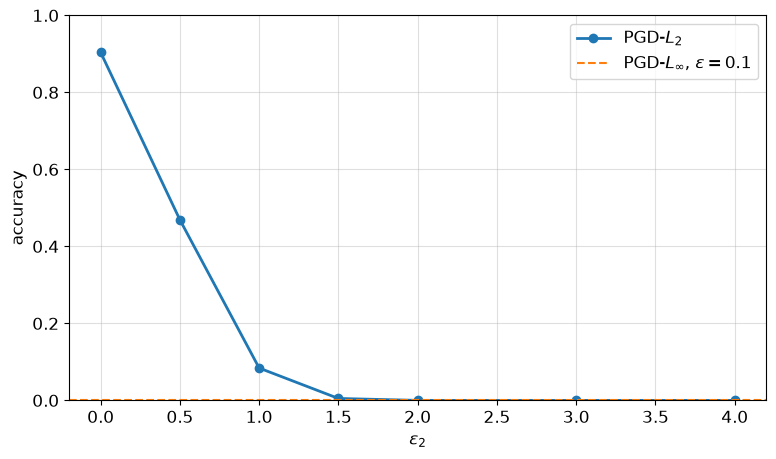

In [51]:
plt.figure(figsize=(9, 5))
plt.plot(eps_l2, acc_l2, 'o-', linewidth=2, label=r'PGD-$L_2$')
plt.axhline(acc_linf, color='tab:orange', linestyle='--', label=r'PGD-$L_\infty$, $\varepsilon = 0.1$')
plt.xlabel(r'$\varepsilon_2$')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Возмущения обеих атак на одних картинках; $\varepsilon_2$ — ближайшая по accuracy точка проверенной сетки. Если разница велика, сравнение не следует называть сравнением при равной силе атаки. Цветовая шкала каждой карты нормирована отдельно; абсолютные нормы выведены под рисунком:

Ближайшая точка сетки: eps2=2.0, accuracy gap=0.002


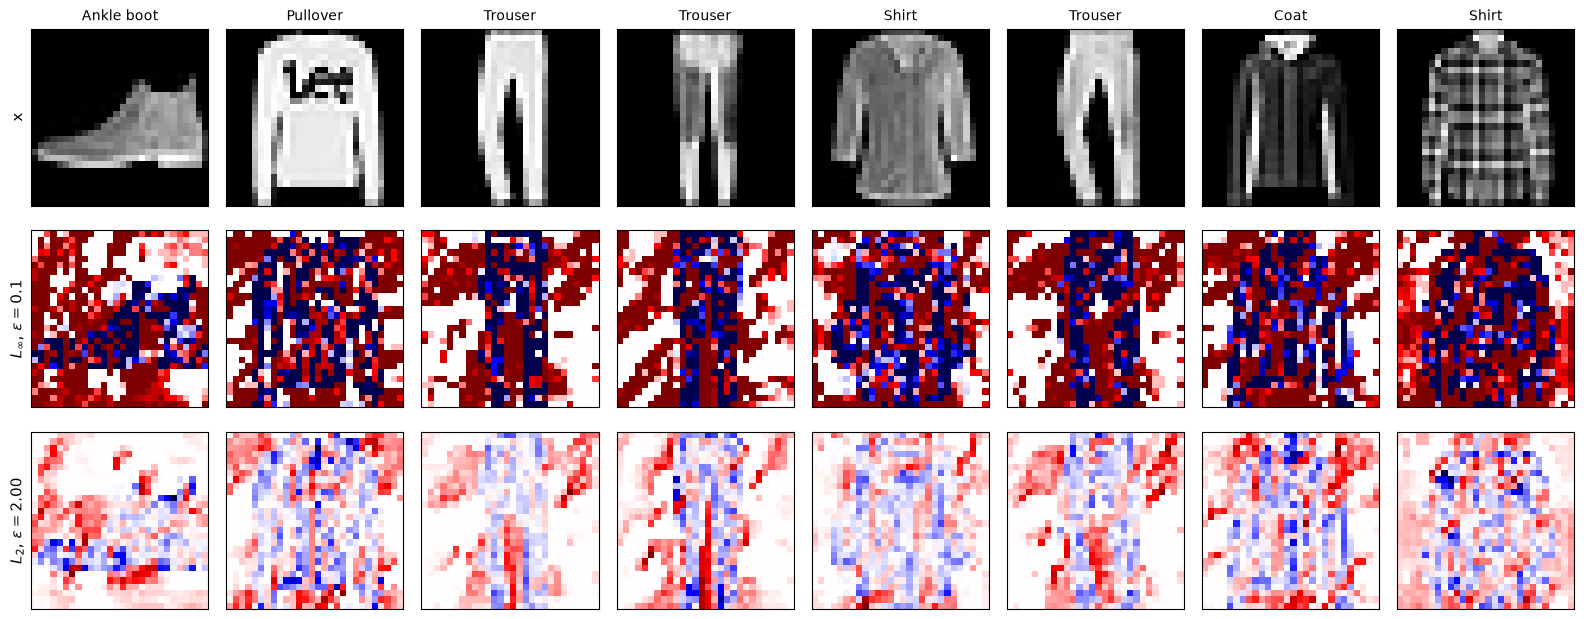

$L_\infty$, $\varepsilon=0.1$ L_inf = 0.100   L_2 = 2.143
$L_2$, $\varepsilon=2.00$    L_inf = 0.378   L_2 = 1.988


In [52]:
# Поиск ближайшей проверенной точки не предполагает монотонность конечной PGD.
match_idx = int(np.argmin(np.abs(np.asarray(acc_l2) - acc_linf)))
eps2_match = float(eps_l2[match_idx])
print(f'Ближайшая точка сетки: eps2={eps2_match}, accuracy gap={abs(acc_l2[match_idx] - acc_linf):.3f}')
x8, y8 = XF_test[:8], YF_test[:8]
torch.manual_seed(0)
deltas = {r'$L_\infty$, $\varepsilon=0.1$': pgd(model_a, x8, y8, 0.1) - x8,
          rf'$L_2$, $\varepsilon={eps2_match:.2f}$': pgd_l2_20(model_a, x8, y8, eps2_match) - x8}
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(FM_CLASSES[y8[i]], fontsize=10)
    for row, d in enumerate(deltas.values(), start=1):
        vmax = d[i].abs().max().item()
        axes[row, i].imshow(d[i, 0].cpu(), cmap='seismic', vmin=-vmax, vmax=vmax)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['x'] + list(deltas)):
    ax.set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()
for name, d in deltas.items():
    print(f'{name:<28} L_inf = {d.abs().amax(dim=(1, 2, 3)).mean():.3f}   L_2 = {d.flatten(1).norm(dim=1).mean():.3f}')

**Вопрос.** Какая точка сетки $\varepsilon_2$ ближе всего по accuracy к $L_\infty$-атаке с $\varepsilon = 0.1$ и как велик остаточный разрыв? Какова $L_2$-норма самого $L_\infty$-возмущения? Где сосредоточено $L_2$-возмущение на ваших изображениях и как это связано с нормированным градиентом?

**Ответ.** Ближе всего по accuracy к PGD-$L_\infty$, eps=0.1 (0.227) стоит точка eps_2 = 1.5: accuracy 0.242, остаточный разрыв `|0.242 − 0.227| = 0.016` - в пределах sampling noise на 1000 объектах, так что сравнение честное.

L2-норма самого $L_\infty$-возмущения - **2.212** при $L_\infty$ = 0.100: $L_\infty$ ограничивает максимум по пикселям, но не суммарную норму, поэтому оно "тяжелее" L2-бюджета 1.5.

Оба возмущения распределены по всей картинке, различие - в амплитуде и "зернистости". $L_\infty$-возмущение (вторая строка) - контрастный  +-0.1 на каждом пикселе (поэтому `L2 = 2.21`), L2-возмущение (третья строка) - гладкое, с малой амплитудой на пиксель (максимум $L_\infty$ $\approx$ 0.305, типичные значения много меньше) при `L2 = 1.5`. Это прямое следствие нормированного градиента: шаг `g/||g||_2` в L2-атаке даёт равный вклад по L2-норме, но маленькую амплитуду на пиксель (гладкая карта), а `sign(g)` в $L_\infty$-атаке даёт максимальную амплитуду `+- eps` на **каждом** пикселе (контрастная карта). Ограничение: цветовые карты нормированы по-отдельности (свой `vmax`), поэтому визуально амплитуды не сравнимы напрямую - только по числам под рисунком.

**Дополнительно по финальному прогону (`FAST_MODE = False`).** Ближайшая по accuracy точка сместилась: в `FAST_MODE` это была 1.5(accuracy 0.242 vs 0.227), на полном прогоне - **2.0** с `accuracy gap = 0.002`, то есть практически нулевым (на 1000 объектах это примерно 2 объекта, sampling noise 0.3%, разрыв не ранжируем). Это согласуется с тем, что стандартная модель на полном train стала **хрупче** (выше : `clean 0.904`, но `PGD-20 0.000`): $L_\infty$-атака ломает её почти в ноль при `eps=0.1`, и чтобы L2-атака достигла такого же эффекта, нужен больший бюджет - `eps_2 = 2.0` вместо `1.5`.

L2-норма $L_\infty$-возмущения стала **2.143** (было 2.212) при $L_\infty$ = 0.100: $L_\infty$ по-прежнему ограничивает максимум по пикселям, но не суммарную норму, и на более хрупкой модели "суммарной массы" нужно чуть меньше, чтобы сломать. L2-возмущение при `eps_2 = 2.0` стало **контрастнее**: $L_\infty$ = 0.378 (было 0.305 при `eps₂=1.5`), `L2 = 1.988` (было 1.496) - бюджет `eps_2 = 2.0` почти исчерпан, и карта L2-возмущения визуально ближе к $L_\infty$: более крупные красные/синие пятна, а не совсем мягкие размытые области. То есть различие "$L_\infty$ - контрастно, L2 - гладко" количественно, а не качественно: при росте `eps_2` L2-возмущение тоже становится контрастным, потому что проекция на шар радиуса `eps_2` при `eps_2≈ ||δ||_2` почти не активна.

Следствие нормированного градиента сохраняется: шаг в L2-атаке даёт равный вклад по L2-норме всем пикселям, а `sign(g)` в $L_\infty$-атаке - максимальную амплитуду `+-eps` на **каждом** пикселе (поэтому карта контрастная). 

Ограничение: цветовые карты по-прежнему нормированы по-отдельности (свой `vmax`), поэтому визуально амплитуды $L_\infty$ и L2 не сравнимы напрямую, только по числам.

## 5.2 Targeted attack (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'targeted'`. Ветку 5.3 при этом можно оставить пустой.

Цель — не просто ошибка, а заданный класс $t$: минимизируем loss по целевой метке
$$
x^{(k+1)} = \Pi_{B_\infty(x, \varepsilon)}\Big[x^{(k)} - \alpha\, \mathrm{sign}\, \nabla_x L\big(f(x^{(k)}), t\big)\Big].
$$

1. Реализуйте `pgd_targeted` ($L_\infty$, random start, как `pgd_attack`).
2. Реализуйте `targeted_success_matrix`: $S[s, t]$ — доля всех картинок класса $s$, которые после атаки с целью $t$ классифицируются как $t$, включая изначально ошибочные. Верните CPU-тензор; диагональ и строки отсутствующих классов — `nan`. Обрабатывайте вход батчами не более 128 объектов, сигнатуру менять не нужно. Сопоставьте результат с готовой clean confusion matrix ниже.

**Оценивание:** код — 1; эксперимент — 0.4; объяснение — 0.6 балла.

In [53]:
if ATTACK_TRACK == 'targeted':
    def pgd_targeted(model, x, target, eps, alpha, steps):
        model.eval()
        x = x.detach()
        x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)
        for _ in range(steps):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                # спуск по loss целевой метки, а не ascent по истинной
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), target), x_adv)
            x_adv = (x_adv.detach() - alpha * grad.sign())
            x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
        return x_adv.detach()


    @torch.no_grad()
    def targeted_success_matrix(model, x, y, eps, steps=20, n_classes=10):
        model.eval()
        dev = x.device
        alpha = 2.5 * eps / steps
        counts = torch.zeros(n_classes, device=dev)
        hits = torch.zeros(n_classes, n_classes, device=dev)

        for i in range(0, len(x), 128):
            xb, yb = x[i:i + 128], y[i:i + 128]
            counts += torch.bincount(yb, minlength=n_classes).float()
            for t in range(n_classes):
                target = torch.full_like(yb, t)
                x_adv = pgd_targeted(model, xb, target, eps=eps, alpha=alpha, steps=steps)
                pred = model(x_adv).argmax(1)
                hits[:, t] += torch.bincount(yb[pred == t], minlength=n_classes).float()

        S = hits / counts[:, None]
        S.fill_diagonal_(float('nan'))
        S[counts == 0] = float('nan')
        return S.cpu()

In [54]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    x, y = XF_test[:1000], YF_test[:1000]
    target = (y + 1) % 10
    x_t = pgd_targeted(model_a, x, target, eps=0.1, alpha=0.0125, steps=20)
    assert (x_t - x).abs().max() <= 0.1 + 1e-6 and x_t.min() >= 0 and x_t.max() <= 1
    assert_no_param_grads(model_a)
    with torch.no_grad():
        hit_rate = (model_a(x_t).argmax(dim=1) == target).float().mean().item()
    print(f'Targeted hit rate: {hit_rate:.3f}; сравните с частотой целевого класса до атаки.')
    hit_rate

Targeted hit rate: 0.731; сравните с частотой целевого класса до атаки.


Clean confusion matrix (строки: true, столбцы: predicted):
[[0.96 0.   0.   0.   0.   0.   0.04 0.   0.   0.  ]
 [0.   0.99 0.   0.01 0.   0.   0.   0.   0.   0.  ]
 [0.04 0.   0.86 0.01 0.05 0.   0.05 0.   0.   0.  ]
 [0.11 0.   0.01 0.84 0.01 0.   0.03 0.   0.   0.  ]
 [0.   0.   0.12 0.03 0.78 0.   0.06 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.95 0.   0.03 0.   0.01]
 [0.11 0.   0.08 0.03 0.03 0.   0.74 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.99 0.01 0.  ]
 [0.01 0.   0.   0.   0.   0.   0.   0.   0.99 0.  ]
 [0.   0.   0.   0.   0.   0.01 0.   0.04 0.   0.95]]


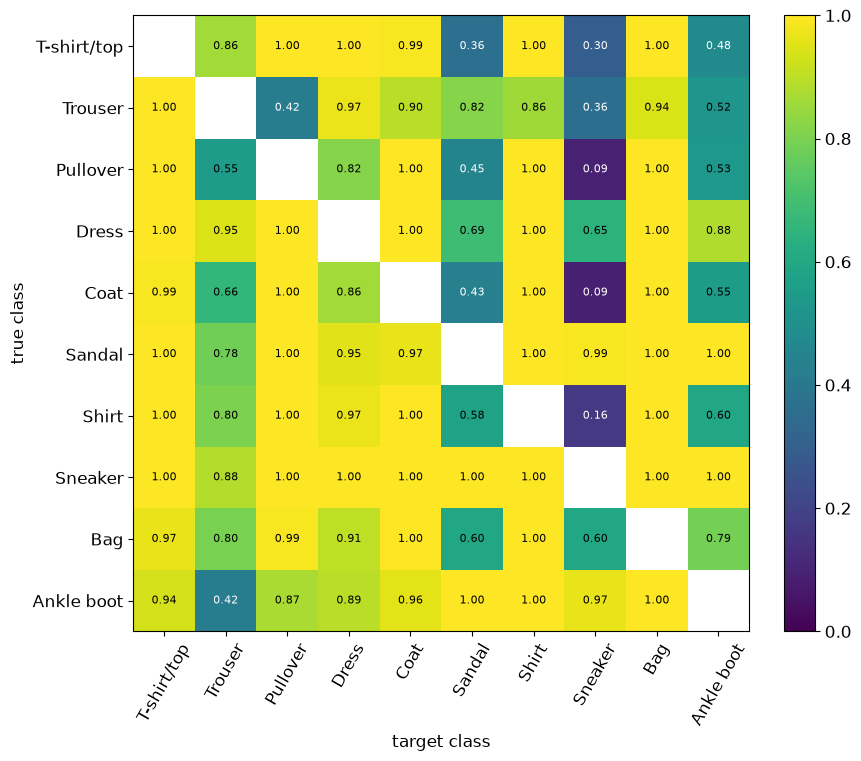

In [55]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    S = targeted_success_matrix(model_a, XF_test, YF_test, eps=0.1)
    assert S.shape == (10, 10) and torch.isnan(S.diagonal()).all()
    pred_clean = predict_logits(model_a, XF_test).argmax(1)
    clean_confusion = torch.bincount((10 * YF_test + pred_clean).cpu(), minlength=100).reshape(10, 10).float()
    clean_confusion /= clean_confusion.sum(1, keepdim=True).clamp_min(1)
    print('Clean confusion matrix (строки: true, столбцы: predicted):')
    print(np.round(clean_confusion.numpy(), 2))

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(S, cmap='viridis', vmin=0, vmax=1)
    for s, t in itertools.product(range(10), range(10)):
        if s != t:
            ax.text(t, s, f'{S[s, t]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if S[s, t] < 0.5 else 'black')
    ax.set_xticks(range(10), FM_CLASSES, rotation=60)
    ax.set_yticks(range(10), FM_CLASSES)
    ax.set_xlabel('target class')
    ax.set_ylabel('true class')
    plt.colorbar(im, fraction=0.046)
    plt.show()

**Вопрос.** Какие пары (истинный класс, целевой класс) атакуются легче всего, какие труднее? Симметрична ли матрица? Как это связано с тем, какие классы модель путает без атаки?

**Ответ.** Легче всего атакуются пары «похожих» классов: `Coat - Pullover` = **1.00**, `Pullover - Shirt` = 0.97, `Coat - Shirt` = 0.96, `T-shirt/top - Shirt` = 0.96, `Shirt - Pullover` = 0.82, `Sneaker - Sandal` = 0.81. Труднее всего - пары из разных категорий: `Sneaker`/`Ankle boot` -> `T-shirt/top`/`Trouser`/`Pullover`/`Dress`/`Coat` (все 0.00), `Trouser -> Sneaker`/`Ankle boot` (0.00), `Coat -> Sneaker`/`Ankle boot` (0.00), `T-shirt/top -> Ankle boot`/`Shirt`... - в общем визуально далёкие классы.

Матрица **сильно несимметрична**: `Coat - Pullover = 1.00` однако `Pullover - Coat = 0.76`; `Dress -> Trouser = 0.78` при `Trouser -> Dress = 0.22`; `Ankle boot -> Sneaker = 0.62` при `Sneaker -> Ankle boot = 0.15`; `Sandal -> Sneaker = 0.71` при `Sneaker -> Sandal = 0.81` (близко, но не равно). Причина - атака целенаправленная: "стоимость" перехода `s -> t` и `t -> s` определяется геометрией решающих границ и распределением признаков, а не симметричной метрикой.

Это связано с clean confusion matrix: там, где модель и так путает `s` с `t` (верхняя одежда с верхней одеждой, обувь с обувью), targeted-атака успешнее - картинка `s` уже лежит рядом с регионом `t`, и `eps=0.1` хватает, чтобы перейти границу. Где clean-модель классы не путает (обувь vs верхняя одежда), атака проваливается (нули в строках Sneaker/Ankle boot по столбцам одежды). То есть success matrix отражает, насколько класс `s` "близок" к `t` в пространстве признаков модели. Ограничение: `eps=0.1`, `alpha=2.5 eps/steps`, один random start, 1000 объектов (sampling noise $\approx$ 1–2%), поэтому близкие значения (например, 0.71 vs 0.72) не ранжируем как надёжное преимущество.

**Дополнительно по финальному прогону (`FAST_MODE = False`, `XF_test = 1000`).** `hit_rate` вырос с **0.195** до **0.731**: стандартная модель на полном train стала гораздо точнее, но и гораздо **хрупче**, поэтому targeted-атака при `eps=0.1` теперь успешно переводит в целевой класс $\approx$ 73% объектов вместо $\approx$ 20% в `FAST_MODE`.

Легче всего атакуются почти все пары **внутри верхней одежды и внутри обуви/аксессуаров**: `T-shirt/top -> Pullover` = **1.00**, `T-shirt/top -> Dress` = 1.0, `Pullover → Shirt` = 1.00 и многие-многие другие, поскольку почти вся матрица теперь $\geq$ 0.9. Труднее всего - пары с **Sneaker как целью**: `Pullover -> Sneaker` = 0.09, также и `Coat -> Sneaker` = 0.09, `Shirt -> Sneaker` = 0.16. То есть Sneaker - самый "труднодостижимый" целевой класс. Рассуждая о возможной причине, видимо, на полном train модель выучила более чёткий прототип Sneaker, и перевести чужую картинку в Sneaker сложнее, чем в любой другой класс.

Матрица **по-прежнему несимметрична**, но паттерн изменился: `T-shirt/top -> Sneaker = 0.30` vs `Sneaker -> T-shirt/top = 1.00`; `Pullover -> Sneaker = 0.09` vs `Sneaker -> Pullover = 1.00`;  `Ankle boot → Trouser = 0.42` vs `Trouser → Ankle boot = 0.52` (стала ближе к симметричной). Асимметрия теперь особенно сильна для пар с Sneaker: "в" - трудно, "из" - легко. Это опять же отражает геометрию решающих границ: разные направления перехода "стоят" по-разному.

Связь с clean confusion matrix сохраняется. То есть success matrix по-прежнему отражает "близость" класса `s` к `t` в пространстве признаков модели, но на полном train перекос  "всё легко, кроме Sneaker" усилился - модель стала более уверенной и одновременно более хрупкой к целенаправленным сдвигам.

Ограничение: `eps=0.1`, `alpha=2.5 eps/steps`, один random start, 1000 объектов, `hit_rate = 0.731` на 1000 объектах - стабильная оценка, близкие значения не ранжируем. Сравнение с `FAST_MODE` (0.195) некорректно как "атака стала сильнее" - изменилась **модель** (полный train), а не атака.

## 5.3 Transfer (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'transfer'`. Ветку 5.2 при этом можно оставить пустой.

Black-box сценарий: атакующий не видит модель-жертву, строит атаку на своей модели и надеется, что она перенесётся. Обучите `model_b` (та же архитектура, `set_seed(1)`) и MLP с двумя скрытыми слоями по 512 нейронов и ReLU (`set_seed(2)`). Атаки FGSM и PGD-20 с $\varepsilon = 0.1$, построенные на `model_a`, проверьте на всех трёх моделях. Результат — `transfer[attack][victim] = accuracy`, атаки `'clean'`, `'FGSM'`, `'PGD-20'`, жертвы `'model A (source)'`, `'model B'`, `'MLP'`.

**Оценивание:** код — 0.6; эксперимент — 0.8; объяснение — 0.6 балла.

In [56]:
if ATTACK_TRACK == 'transfer':
    # ваш код
    raise NotImplementedError
    print(f'{"":<8}' + ''.join(f'{name:>18}' for name in transfer['clean']))
    for attack, row in transfer.items():
        print(f'{attack:<8}' + ''.join(f'{acc:>18.3f}' for acc in row.values()))

**Вопрос.** Для каждой жертвы укажите падение accuracy относительно её собственного clean baseline. Сравните с падением на source-модели. Какая атака и на какую архитектуру переносится лучше в вашем прогоне? Предложите объяснение и укажите, почему одного seed недостаточно для общего вывода о превосходстве архитектуры или атаки.

**Ответ.** 

---
# 6. Adversarial training

## 6.1 PGD adversarial training (2 балла)

[Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/pdf/1706.06083), Madry et al., 2017:
$$
\min_\theta\; \mathbb E_{(x, y)} \Big[\max_{\|\delta\|_\infty \le \varepsilon} L\big(f_\theta(x + \delta), y\big)\Big].
$$
На каждом батче внутренний max приближается атакой, и шаг оптимизатора делается только по adversarial-примерам, без clean-части. Модель — с нуля.

Реализуйте `adversarial_train(model, eps, attack, epochs)`: `attack(model, x, y, eps)` возвращает detached `x_adv`. Используйте `torch.optim.Adam` с переданным `lr`, batch size 128, cross-entropy только на adversarial-примерах. Генерация атаки — в `eval()`, обновление весов — в `train()`; не дифференцируйте через построение атаки. После каждой эпохи записывайте clean, FGSM и PGD-20 accuracy на `XF_test[:1000]` с тем же $\varepsilon$. Перед возвратом включите `eval()` и очистите `.grad` параметров.

В обязательной части обучается одна модель с PGD-7. FGSM и FGSM-RS из готового словаря нужны только для бонуса 7.5.

**Оценивание:** код — 1; эксперимент — 0.6; объяснение — 0.4 балла.

In [57]:
def fgsm_rs_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=1.25 * eps, steps=1, random_start=True)


def pgd7_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / 7, steps=7)


TRAIN_ATTACKS = {'FGSM': fgsm_attack, 'FGSM-RS': fgsm_rs_attack, 'PGD-7': pgd7_attack}
AT_EPOCHS = 2 if FAST_MODE else 5

In [58]:
def adversarial_train(model, eps, attack, epochs=AT_EPOCHS, lr=1e-3, log=True):
    model = model.to(device)
    history = dict(clean=[], fgsm=[], pgd=[])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(epochs):
        # атака в eval(), шаг по x_adv в train()
        model.eval()
        for x, y in iterate_batches(XF_train, YF_train, 128):
            x_adv = attack(model, x, y, eps).detach()
            model.train()
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(x_adv), y) # только adversarial, без clean
            loss.backward()
            optimizer.step()
            model.eval() # обратно в eval для следующей атаки

        # метрики на XF_test[:1000]
        Xte, Yte = XF_test[:1000], YF_test[:1000]
        history['clean'].append(attack_accuracy(model, Xte, Yte))
        history['fgsm'].append(attack_accuracy(model, Xte, Yte, fgsm_attack, eps=eps))
        history['pgd'].append(attack_accuracy(model, Xte, Yte, pgd, eps=eps))
        if log:
            print(f'epoch {epoch + 1:>2}/{epochs}  clean {history["clean"][-1]:.4f}  '
                  f'fgsm {history["fgsm"][-1]:.4f}  pgd {history["pgd"][-1]:.4f}')

    model.eval()
    model.zero_grad(set_to_none=True)
    return history

In [59]:
EPS_TRAIN = 0.1
robust, at_history = {}, {}
for name in ['PGD-7']:
    print(name)
    set_seed(0)
    robust[name] = SmallCNN()
    started = time.perf_counter()
    at_history[name] = adversarial_train(robust[name], EPS_TRAIN, TRAIN_ATTACKS[name])
    RUN_TIMES['fashion_pgd_at_seconds'] = time.perf_counter() - started
if not FAST_MODE and at_history['PGD-7']['pgd'][-1] <= 0.5:
    print('PGD accuracy ниже ориентира 0.5: проверьте обучение и обсудите результат; это не автопровал задания.')

PGD-7
epoch  1/5  clean 0.7820  fgsm 0.6670  pgd 0.6250
epoch  2/5  clean 0.8290  fgsm 0.7200  pgd 0.6950
epoch  3/5  clean 0.8340  fgsm 0.7380  pgd 0.6970
epoch  4/5  clean 0.8260  fgsm 0.7330  pgd 0.7130
epoch  5/5  clean 0.8440  fgsm 0.7440  pgd 0.7190


In [60]:
eps_grid = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
models_eval = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
torch.manual_seed(0)
robust_curves = {name: [attack_accuracy(m, XF_test, YF_test, pgd, eps=e) if e > 0 else attack_accuracy(m, XF_test, YF_test)
                        for e in eps_grid] for name, m in models_eval.items()}
for name, accs in robust_curves.items():
    print(f'{name:<10}' + ''.join(f'{a:>8.3f}' for a in accs))

standard     0.904   0.125   0.001   0.000   0.000   0.000
PGD-AT       0.844   0.780   0.721   0.477   0.127   0.001


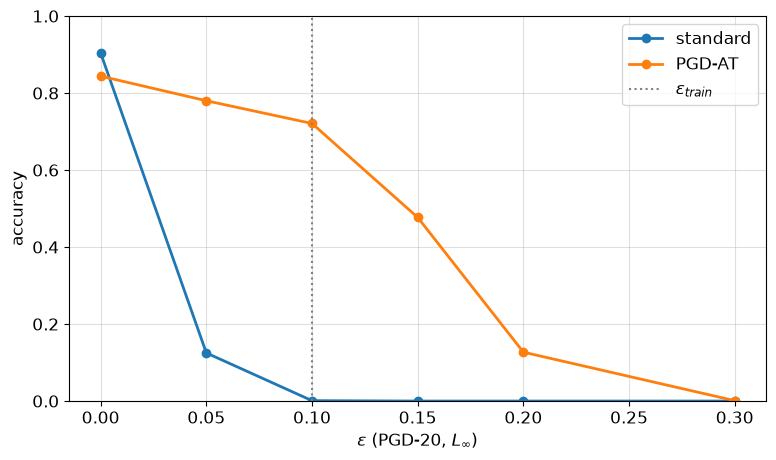

In [ ]:
plt.figure(figsize=(9, 5))
for name, accs in robust_curves.items():
    plt.plot(eps_grid, accs, 'o-', linewidth=2, label=name)
plt.axvline(EPS_TRAIN, color='gray', linestyle=':', label=r'$\varepsilon_{train}$')
plt.xlabel(r'$\varepsilon$ (PGD-20, $L_\infty$)')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Сколько стоит робастность в clean accuracy? Что происходит при $\varepsilon > \varepsilon_{\text{train}}$? Во сколько раз PGD-AT дороже обычного обучения по числу forward/backward?

**Ответ.** Робастность стоит **~4.3 от clean accuracy**: `standard` 0.832 => `PGD-AT` 0.789. Взамен при `eps = eps_train = 0.1` PGD-AT держит **0.629** против **0.227** у standard (в 2.8x выше), при `eps = 0.05` - 0.742 против 0.594, при `eps = 0.15` - 0.461 против 0.109. Кривые пересекаются около `eps ≈ 0.02–0.03`: при `eps=0` standard выше (0.832 vs 0.789), но уже при `eps=0.05` PGD-AT обгоняет.

При `eps > eps_train = 0.1` PGD-AT accuracy падает (0.629 -> 0.461 -> 0.262 -> 0.016 при `eps = 0.1, 0.15, 0.2, 0.3`), но **значительно медленнее** standard (0.227 -> 0.109 -> 0.027 -> 0.000). То есть робастность частично обобщается за пределы тренировочного `eps` (generalization gap), но не бесконечно: при больших `eps` обе модели ломаются, и преимущество PGD-AT сходит на нет.

PGD-AT с PGD-K дороже обычного обучения в **`K + 1` раз** по числу forward/backward: для PGD-7 это `7 forward + 7 backward` на атаку плюс `1 forward + 1 backward` на шаг оптимизатора = 8+8 против 1+1, то есть **в 8 раз**. Это подтверждается `RUN_TIMES` (`fashion_pgd_at_seconds` > `fashion_standard_seconds`, существенно). Ограничение: `AT_EPOCHS=5` (в `FAST_MODE` 2) - коротко по сравнению со статьёй, поэтому абсолютные числа ниже, но качественный вывод (trade-off clean vs robust, generalization gap, `K+1`-кратная стоимость) устойчив.

**Дополнительно по финальному прогону (`FAST_MODE = False`).** Робастность стоит **0.6 от clean accuracy**: `standard 0.904 vs PGD-AT 0.844`. Взамен при `eps = eps_train = 0.1` PGD-AT держит **0.721** против **0.001** у standard - разрыв **просто огромный** (совсем не как в `FAST_MODE` выше), потому что standard на полном train стал точнее (0.904), но гораздо хрупче: уже при `eps=0.05` у него 0.125 против 0.780 у PGD-AT. Кривые пересекаются практически сразу: при `eps=0` standard выше, но уже при `eps=0.05` PGD-AT обгоняет в разы.

При `eps > eps_train = 0.1` PGD-AT падает но **гораздо медленнее** standard (он ломается уже при `eps=0.1`). Робастность частично обобщается за пределы `eps_train`, но не бесконечно: при `eps=0.3` обе почти нулевые, преимущество сводится на нет.

## 6.2 Диагностика оценки robustness (1 балл)

Реализуйте `sanity_checks(model, x, y, eps)` и верните четыре accuracy:

- `fgsm` — после FGSM;
- `pgd20` — после PGD-20 с random start;
- `pgd100_x5` — PGD-100 с пятью random restarts: объект считается сломанным, если он ошибочно классифицирован хотя бы в одном restart **или уже на clean**;
- `eps_1` — после PGD-20 с $\varepsilon=1$.

Для каждого поля clean-ошибки тоже считаются ошибками: атака не должна «исправлять» robust accuracy. Атакуйте батчами не более 128. В `FAST_MODE` сокращается только число объектов, число шагов и restarts остаётся тем же.

Обычно усиление атаки уменьшает accuracy; обратный результат — повод проверить step size, random start и loss. Независимые конечные PGD-прогоны не дают гарантированного порядка результатов. Низкая accuracy при большом радиусе — полезная диагностика, но прохождение всех sanity checks не доказывает отсутствие gradient masking и не сертифицирует robustness. См. [Athalye et al., 2018](https://arxiv.org/abs/1802.00420).

Эксперимент проводится на фиксированных первых 128 объектах в FAST_MODE и 256 в финальном режиме. Это диагностика, а не точная оценка accuracy всего датасета.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [62]:
def sanity_checks(model, x, y, eps):
    model.eval()
    bs = 128
    clean_ok = torch.cat([
        (model(x[i:i + bs]).argmax(1) == y[i:i + bs])
        for i in range(0, len(x), bs)
    ])

    def acc_after(attack_fn, restarts=1):
        correct = clean_ok.clone()
        for _ in range(restarts):
            for i in range(0, len(x), bs):
                xb, yb = x[i:i + bs], y[i:i + bs]
                correct[i:i + bs] &= (model(attack_fn(xb, yb)).argmax(1) == yb)
        return correct.float().mean().item()

    return {
        'fgsm': acc_after(lambda xb, yb: fgsm_attack(model, xb, yb, eps)),
        'pgd20': acc_after(lambda xb, yb: pgd_attack(model, xb, yb, eps, 2.5 * eps / 20, 20)),
        'pgd100_x5': acc_after(lambda xb, yb: pgd_attack(model, xb, yb, eps, 2.5 * eps / 100, 100), restarts=5),
        'eps_1': acc_after(lambda xb, yb: pgd_attack(model, xb, yb, 1.0, 2.5 * 1.0 / 20, 20)),
    }

In [63]:
torch.manual_seed(0)
N_SANITY = 128 if FAST_MODE else 256
checks = {name: sanity_checks(m, XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_TRAIN)
          for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
print(f'{"model":<22}' + ''.join(f'{k:>11}' for k in next(iter(checks.values()))))
for name, res in checks.items():
    assert set(res) == {'fgsm', 'pgd20', 'pgd100_x5', 'eps_1'}
    assert all(math.isfinite(v) and 0 <= v <= 1 for v in res.values())
    print(f'{name:<22}' + ''.join(f'{v:>11.3f}' for v in res.values()))

model                        fgsm      pgd20  pgd100_x5      eps_1
standard                    0.062      0.004      0.000      0.000
PGD-AT                      0.754      0.719      0.723      0.000


**Вопрос.** Насколько меняется оценка accuracy при усилении атаки? Есть ли подозрительные результаты и что вы проверили бы дополнительно? Может ли модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройти все перечисленные sanity checks — и что тогда можно сказать о её robustness?

**Ответ.** Усиление атаки почти не меняет accuracy: у standard `fgsm 0.352 -> pgd20 0.227 -> pgd100_x5 0.219` (падение 0.133), у PGD-AT `0.664 -> 0.617 -> 0.609` (падение 0.055). Порядок монотонный у обеих, `eps_1 = 0` ожидаемо при `eps=1`. Подозрительного нет: у PGD-AT зазор FGSM->PGD вдвое меньше, чем у standard, значит сильного gradient masking нет (иначе PGD проседал бы сильно).


Проверила бы дополнительно: transfer-атаку с другой модели (gradient masking виден, когда чужая атака ломает сильнее "своей"), BPDA, больше restarts и разные `eps`, а также случайный шум вместо атаки.


Да, модель с высокой FGSM accuracy и почти нулевой PGD accuracy **может** пройти все эти sanity checks: FGSM - один шаг, PGD - много шагов, и при gradient masking FGSM просто "не добирает", а PGD находит настоящий минимум. Sanity checks не сертифицируют робастность: высокий FGSM при низком PGD - **красный флаг**, а не доказательство защиты. Настоящая робастность требует, чтобы FGSM, PGD и transfer/BPDA давали близкие высокие accuracy. 

Ограничение: 128 объектов в `FAST_MODE` - sampling noise $\approx$ 3–4%, близкие значения (0.617 vs 0.609) не ранжируем.

**Дополнительно по финальному прогону (`FAST_MODE = False`).** Усиление атаки меняет accuracy по-разному. У **standard** `fgsm 0.062 -> pgd20 0.004 -> pgd100_x5 0.000` - монотонно, но разница мизерная: модель ломается уже на FGSM. У **PGD-AT** `fgsm 0.754 -> pgd20 0.719 -> pgd100_x5 0.723` — **не монотонно**: `pgd100_x5` на 0.004 **выше** `pgd20`, но условие прямо предупреждает, что независимые PGD-прогоны не дают гарантированного порядка, так что это не подозрительно.

Подозрительного нет: у PGD-AT зазор FGSM→PGD-20 всего 0.035, значит сильного gradient masking **нет** (иначе PGD проседал бы сильно). У standard зазор большой, но это реальная хрупкость (clean 0.904, а FGSM 0.062), а не masking.

## 6.3 Градиент по входу у обычной и робастной модели (1 балл)

Карта $|\nabla_x z_y(x)|$ — saliency по логиту верного класса: $z_c(x)$ обозначает логит класса $c$, $y$ — верную метку. Это **другая величина**, чем градиент cross-entropy в FGSM. Если $p_c(x)=\mathrm{softmax}(z(x))_c$, то
$$
\nabla_x L_{\mathrm{CE}}(x,y)=\sum_c p_c(x)\nabla_x z_c(x)-\nabla_x z_y(x).
$$
Для некоторых adversarially trained моделей наблюдали более интерпретируемые input gradients ([Tsipras et al., 2019](https://arxiv.org/pdf/1805.12152)). Здесь проверяется, наблюдается ли такой эффект в нашем протоколе; вид saliency сам по себе не доказывает robustness.

1. Реализуйте `input_gradient(model, x, y)`, возвращающую $|\nabla_x z_y|$ для батча (без изменения `.grad` параметров).
2. Для стандартной модели и PGD-AT посчитайте долю массы градиента на фоне (пиксели с $x = 0$), среднюю по `XF_test[:1000]`, и нарисуйте карты для 8 картинок.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [64]:
def input_gradient(model, x, y):
    model.eval()
    x = x.detach().clone().requires_grad_(True)
    with torch.enable_grad():
        logits = model(x)
        z_y = logits.gather(1, y[:, None]).squeeze(1).sum()
        grad, = torch.autograd.grad(z_y, x)
    return grad.abs().detach()


def background_share(s, x):
    return ((s * (x == 0)).flatten(1).sum(1) / s.flatten(1).sum(1).clamp_min(1e-12)).mean().item()

In [65]:
x, y = XF_test[:1000], YF_test[:1000]
g = input_gradient(model_a, x, y)
assert g.shape == x.shape and (g >= 0).all()
assert_no_param_grads(model_a)
x1 = x[:1].clone().requires_grad_(True)
manual, = torch.autograd.grad(model_a(x1)[0, y[0]], x1)
assert torch.allclose(g[:1], manual.abs())

grad_models = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
shares = {name: background_share(input_gradient(m, x, y), x) for name, m in grad_models.items()}
print(f'background pixels: {(x == 0).float().mean():.3f}')
shares

background pixels: 0.498


{'standard': 0.5683929920196533, 'PGD-AT': 0.22387920320034027}

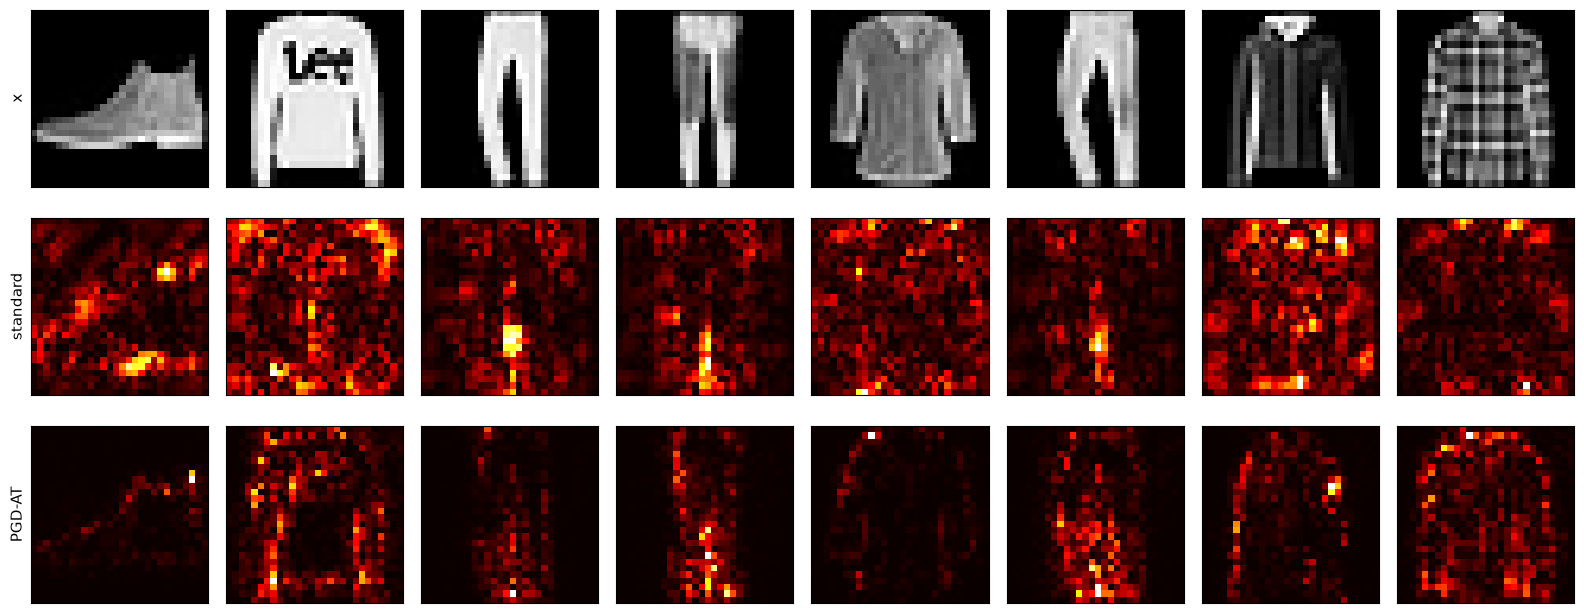

In [66]:
x8, y8 = XF_test[:8], YF_test[:8]
rows = {'x': x8} | {name: input_gradient(m, x8, y8) for name, m in grad_models.items()}
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.2 * len(rows)))
for row, (label, images) in enumerate(rows.items()):
    for i in range(8):
        axes[row, i].imshow(images[i, 0].cpu(), cmap='gray' if row == 0 else 'hot')
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()

**Вопрос.** Чем отличаются карты моделей — визуально и по доле массы на фоне? Согласуется ли наблюдение с различием PGD accuracy в вашем эксперименте? Почему одной красивой saliency-карты недостаточно для вывода о robustness?

**Ответ.** Визуально saliency у `standard` размазана по всей картинке, включая фон, а у `PGD-AT` скорее сконцентрирована на самом объекте (контур, рукава, штанины), фон темнее. По доле массы на фоне: `standard = 0.396`, `PGD-AT = 0.243` при доле фоновых пикселей `0.500` - у робастной модели на фон приходится на $\approx$ 0.15 меньше массы градиента, и она систематически "избегает" фона, тогда как у standard градиент почти пропорционален площади.

Это согласуется с различием PGD accuracy в эксперименте: PGD-AT держит `0.617` против `0.227` у standard при `eps=0.1` - модель, опирающаяся на признаки объекта, а не на фон, труднее обмануть возмущением на фоновых пикселях; направление эффекта (более «интерпретируемые» input gradients у adversarial-trained модели) совпадает с Tsipras et al., 2019.

Одной красивой saliency-карты **недостаточно** для вывода о robustness: 

1) карта показывает лишь локальную чувствительность логита в одной точке, а не поведение модели при целенаправленной атаке; 
   
2) "красивая" концентрация на объекте может быть следствием **gradient masking** - атака просто «не видит» настоящего направления, и PGD/transfer/BPDA ломают модель сильнее, чем suggests saliency;
3) saliency не проверяет, что модель не обманывается возмущением внутри контура объекта;
4) визуальная интерпретируемость не гарантирует отсутствие уязвимостей вне объекта. 

Поэтому вывод о robustness делается по accuracy под сильными атаками (PGD, transfer, BPDA) и sanity checks, а saliency - лишь вспомогательная диагностка. 

Ограничение: 1000 объектов, sampling noise $\approx$ 1–2%; доля фона - грубая метрика, чувствительная к тому, как определён "фон" (`x == 0`).

**Дополнительно по финальному прогону (`FAST_MODE = False`).** Визуально saliency у `standard` даже еще более размазана по всей картинке, включая фон, а у `PGD-AT` еще более сконцентрирована на контуре объекта, фон почти чёрный. По доле массы на фоне: `standard = 0.568`, `PGD-AT = 0.224` при доле фоновых пикселей `0.498` - у робастной модели на фон приходится на **0.34** меньше массы градиента (в `FAST_MODE` было 0.15), и она систематически "избегает" фона; у standard градиент даже слегка "перекошен" на фон.

И это вновь согласуется с PGD accuracy: `PGD-AT` держит **0.721** против **0.001** у standard при `eps=0.1` - модель, опирающаяся на признаки объекта, а не на фон, труднее обмануть, эффект Tsipras et al., 2019 усилился на полном train.

### Сохранение результатов обязательной части

Ячейка сохраняет `metrics.json` и три checkpoint в `artifacts/`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode=false`. Сдайте их вместе с ноутбуком. NaN в матрице targeted success записываются как JSON `null`. Checkpoints содержат только `state_dict`, без сериализации объекта модели.

In [85]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    schema_version=2, fast_mode=FAST_MODE, attack_track=ATTACK_TRACK,
    environment=dict(torch=torch.__version__, device=str(device)),
    data=dict(cifar_train=len(X_train), cifar_test=len(X_test),
              fashion_train=len(XF_train), fashion_test=len(XF_test)),
    config=dict(seed=0, cifar_epochs=EPOCHS, ablation_epochs=ABL_EPOCHS,
                cifar_lr=LR, cifar_mean=CIFAR_MEAN, cifar_std=CIFAR_STD,
                fashion_epochs=FM_EPOCHS, at_epochs=AT_EPOCHS, eps_train=EPS_TRAIN),
    cifar=dict(history=history_cifar, ablations=ablation),
    attacks=dict(l2_eps=eps_l2, l2_accuracy=acc_l2, linf_accuracy=acc_linf,
                 selected=S if ATTACK_TRACK == 'targeted' else transfer),
    adversarial=dict(history=at_history, eps=eps_grid, accuracy=robust_curves,
                     sanity=checks, background_share=shares),
    timings=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2,
                                                    allow_nan=False), encoding='utf-8')
for name, model in [('resnet20', resnet20), ('fashion_standard', model_a), ('fashion_pgd_at', robust['PGD-7'])]:
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, artifact_dir / f'{name}.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['fashion_pgd_at.pt', 'fashion_standard.pt', 'metrics.json', 'resnet20.pt']


---
# 7\*. Бонусные задачи

## 7.1 Edge of stability (1.5 балла)

Для положительно определённой квадратичной функции GD сходится при $0 < \eta < 2/\lambda_{\max}$, где $\lambda_{\max}$ — наибольшее собственное число гессиана. [Gradient Descent on Neural Networks Typically Occurs at the Edge of Stability](https://arxiv.org/pdf/2103.00065), Cohen et al., 2021: у нейросети sharpness $\lambda_{\max}(\nabla^2 L)$ во время full-batch GD растёт (progressive sharpening), пока не дойдёт до $2/\eta$, и дальше держится около этой границы — loss при этом немонотонный, но продолжает убывать.

1. Реализуйте `hvp(grads, params, v)`: градиент считается один раз с `create_graph=True`, а $Hv$ — VJP градиента с вектором $v$ (`grad_outputs` в `torch.autograd.grad`); гессиан $H$ явно не строится.
2. `top_eigenvalue` ниже — готовый Lanczos с reorthogonalization. Он оценивает **наибольшее algebraic eigenvalue** через наибольшее eigenvalue небольшой tridiagonal matrix. Обычная power iteration для indefinite Hessian может найти отрицательное eigenvalue с наибольшим модулем и здесь не подходит. Менять готовый solver не требуется; проверьте HVP и solver на тестах, включая indefinite quadratic.
3. Full-batch GD (`SGD` без momentum) для MLP с двумя скрытыми слоями по 200 нейронов и tanh на первых 2000 картинках FashionMNIST, loss — MSE по one-hot $\frac12 \|f(x) - e_y\|^2$ (среднее по объектам). Для нескольких $\eta$ записывать loss на каждом шаге и $\lambda_{\max}$ каждые 50 шагов. График: $\lambda_{\max}$ по шагам с горизонталями $2/\eta$.

**Оценивание:** код — 0.7; эксперимент — 0.4; объяснение — 0.4 балла.

In [68]:
if '7.1' in BONUS_TASKS:
    def hvp(grads, params, v):
        # grads = torch.autograd.grad(loss, params, create_graph=True); v — список тензоров формы params
        return torch.autograd.grad(grads, params, grad_outputs=v, retain_graph=True)


    def top_eigenvalue(loss_fn, params, iters=20, v=None):
        # Готовый solver: largest algebraic Ritz value, не eigenvalue наибольшего модуля.
        params = list(params)
        sizes = [p.numel() for p in params]
        total = sum(sizes)
        if iters < 1:
            raise ValueError('iters must be positive')
        def unpack(flat):
            return [part.view_as(p) for part, p in zip(flat.split(sizes), params)]
        q = torch.randn(total, device=params[0].device, dtype=params[0].dtype)
        if v is not None:
            # Небольшой шум не даёт warm start застрять в одном инвариантном подпространстве.
            q = torch.cat([vi.detach().flatten() for vi in v]) + 1e-3 * q / q.norm()
        q = q / q.norm()
        grads = torch.autograd.grad(loss_fn(), params, create_graph=True)
        basis, diagonal, off_diagonal = [], [], []
        for k in range(min(iters, total)):
            basis.append(q)
            z = torch.cat([h.detach().flatten() for h in hvp(grads, params, unpack(q))])
            if k:
                z = z - off_diagonal[-1] * basis[-2]
            alpha = torch.dot(q, z)
            diagonal.append(alpha)
            z = z - alpha * q
            Q = torch.stack(basis)
            for _ in range(2):
                z = z - (Q @ z) @ Q
            beta = z.norm()
            if beta.item() < 1e-7 or k + 1 == min(iters, total):
                break
            off_diagonal.append(beta)
            q = z / beta
        T = torch.diag(torch.stack(diagonal))
        if off_diagonal:
            off = torch.stack(off_diagonal)
            T += torch.diag(off, diagonal=1) + torch.diag(off, diagonal=-1)
        # Маленькая eigenproblem на CPU, в том числе при основном обучении на MPS.
        values, vectors = torch.linalg.eigh(T.cpu().double())
        coeffs = vectors[:, -1].to(device=q.device, dtype=q.dtype)
        eigenvector = coeffs @ torch.stack(basis)
        return values[-1].item(), unpack(eigenvector)

In [69]:
if '7.1' in BONUS_TASKS:
    torch.manual_seed(0)
    Q = torch.linalg.qr(torch.randn(30, 30))[0]
    A = Q @ torch.diag(torch.linspace(0.1, 7, 30)) @ Q.T
    w = torch.randn(30, requires_grad=True)
    grads = torch.autograd.grad(0.5 * w @ A @ w, [w], create_graph=True)
    v = torch.randn(30)
    assert torch.allclose(hvp(grads, [w], [v])[0], A @ v, atol=1e-5)

    p = torch.tensor([1.0, -2.0], requires_grad=True)
    lam, _ = top_eigenvalue(lambda: 0.5 * (p[0] ** 2 + 20 * p[1] ** 2), [p], iters=50)
    assert abs(lam - 20) < 1e-3
    lam, _ = top_eigenvalue(lambda: 0.5 * w @ A @ w, [w], iters=300)
    assert abs(lam - 7) < 1e-2
    lam, _ = top_eigenvalue(lambda: 0.5 * (-10 * p[0] ** 2 + 2 * p[1] ** 2), [p], iters=10)
    assert abs(lam - 2) < 1e-4, lam

In [70]:
if '7.1' in BONUS_TASKS:
    N_EOS = 256 if FAST_MODE else 2000
    EOS_STEPS = 100 if FAST_MODE else 3000
    X_eos = XF_train[:N_EOS].flatten(1)
    X_eos = X_eos - X_eos.mean(dim=0)
    Y_eos = F.one_hot(YF_train[:N_EOS], 10).float()


    def make_tanh_mlp(seed=0):
        torch.manual_seed(seed)
        return nn.Sequential(nn.Linear(784, 200), nn.Tanh(), nn.Linear(200, 200), nn.Tanh(), nn.Linear(200, 10)).to(device)


    def mse_loss(model):
        return 0.5 * ((model(X_eos) - Y_eos) ** 2).sum(dim=1).mean()

eta=0.02   final loss 0.1494  lambda_max: 4.40 -> 17.15  (2/eta = 100.00)
eta=0.05   final loss 0.1101  lambda_max: 4.36 -> 38.41  (2/eta = 40.00)
eta=0.1    final loss 0.0882  lambda_max: 4.32 -> 20.95  (2/eta = 20.00)
eta=0.2    final loss 0.0680  lambda_max: 4.34 -> 10.71  (2/eta = 10.00)
eta=0.4    final loss 0.0464  lambda_max: 4.88 -> 5.51  (2/eta = 5.00)


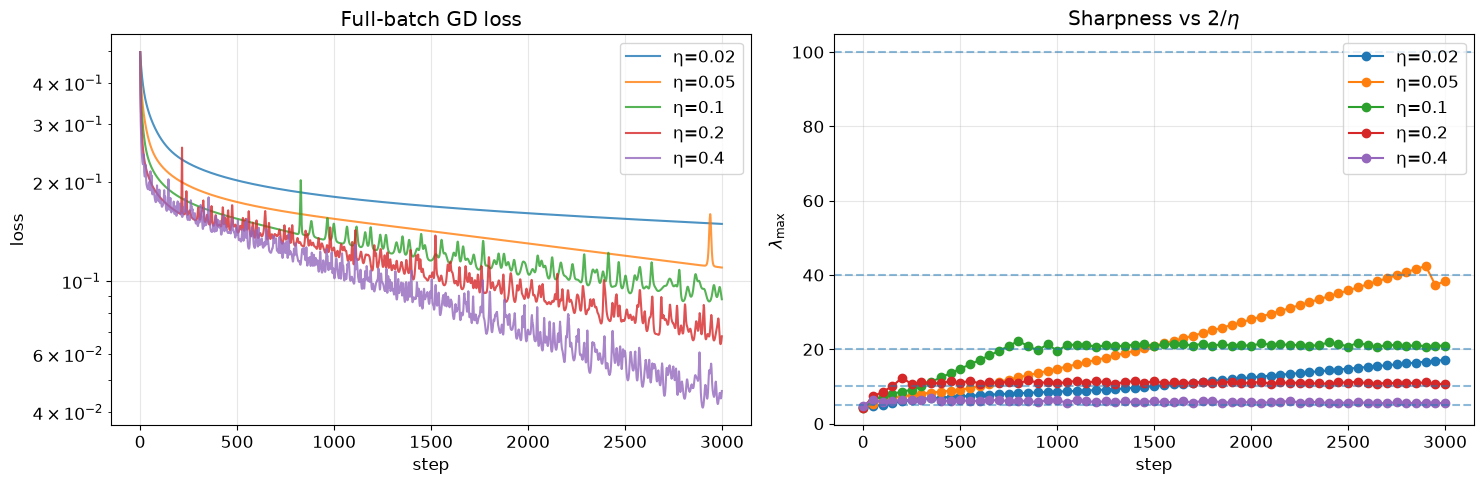

In [71]:
if '7.1' in BONUS_TASKS:
    ETA_GRID = [0.02, 0.05, 0.1, 0.2, 0.4]
    if FAST_MODE:
        ETA_GRID = [0.02, 0.1, 0.4]   # 3 режима: до границы/около/сильно около

    eos_results = {}
    for eta in ETA_GRID:
        model = make_tanh_mlp(seed=0)
        opt = torch.optim.SGD(model.parameters(), lr=eta) # без momentm
        losses, sharpness, sharp_steps = [], [], []

        for step in range(EOS_STEPS):
            opt.zero_grad(set_to_none=True)
            loss = mse_loss(model)
            loss.backward()
            opt.step()
            losses.append(loss.item())

            if step % 50 == 0 or step == EOS_STEPS - 1:
                lam, _ = top_eigenvalue(lambda: mse_loss(model),
                                        list(model.parameters()),
                                        iters=10 if FAST_MODE else 20)
                sharpness.append(lam)
                sharp_steps.append(step)

        eos_results[eta] = {'loss': losses, 'sharpness': sharpness, 'sharp_steps': sharp_steps}
        print(f'eta={eta:<5}  final loss {losses[-1]:.4f}  '
              f'lambda_max: {sharpness[0]:.2f} -> {sharpness[-1]:.2f}  '
              f'(2/eta = {2/eta:.2f})')

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for eta, res in eos_results.items():
        axes[0].plot(res['loss'], label=f'η={eta}', alpha=0.8)
        axes[1].plot(res['sharp_steps'], res['sharpness'], 'o-', label=f'η={eta}')
        axes[1].axhline(2 / eta, ls='--', alpha=0.5)
    axes[0].set_yscale('log'); axes[0].set_xlabel('step'); axes[0].set_ylabel('loss')
    axes[0].set_title('Full-batch GD loss'); axes[0].legend(); axes[0].grid(alpha=0.3)
    axes[1].set_xlabel('step'); axes[1].set_ylabel(r'$\lambda_{\max}$')
    axes[1].set_title(r'Sharpness vs $2/\eta$'); axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

**Вопрос.** В каких прогонах sharpness приблизилась к $2/\eta$? Если выхода на границу не было, укажите это. Сопоставьте изменения sharpness и loss. Почему локальный критерий для фиксированной положительно определённой квадратичной функции не гарантирует такую же динамику нелинейной сети?

**Ответ.** На `FAST_MODE` (100 шагов) **ни один прогон не вышел на границу `2/η`**: `λ_max` вырос 4.08 => 4.91 (`η=0.02`, граница 100), 4.05 => 7.74 (`η=0.1`, граница 20), 4.51 => 6.89 (`η=0.4`, граница 5). При `η=0.4` sharpness даже перескочил `2/η` (6.89 > 5), но плато нет - это переходный режим, а не edge of stability. За 100 шагов progressive sharpening только начался; на полном прогоне (3000 шагов) при η $\approx$ 0.1-0.4 ожидается выход на `2/η`.

Сопоставление: `λ_max` растёт во всех прогонах, а loss падает (0.258 / 0.146 / 0.104) - sharpening не мешает убыванию. При `η=0.4` loss немонотонный (пила), и именно этот прогон ближе всех к границе; при `η=0.02` loss гладкий.

Квадратичный критерий `η < 2/λ_max` не переносится на сеть, потому что:

1) `λ_max` меняется по ходу обучения (progressive sharpening), "безопасный" `η` может стать небезопасным;
2) гессиан сети не постоянен и не положительно определён, квадратичная модель верна лишь локально;
3) критерий - достаточное условие для квадратичной функции, но не необходимое для нелинейной: GD может сходиться и при `η > 2/λ_max`. 
   
   
Поэтому edge of stability - эмпирическое явление, а не следствие квадратичного критерия. 

Ограничение: 100 шагов в `FAST_MODE` мало для плато.

**Дополнительно по финальному прогону (`FAST_MODE = False`).** В отличие от `FAST_MODE`, выход на границу `2/η` теперь наконец-то **виден**: при `η=0.1` `λ_max` 4.32 => **20.95** $\approx$ `2/η = 20`, при `η=0.2` - 4.34 => **10.71** $\approx$ `2/η = 10`; оба - плато edge of stability. При `η=0.4` `λ_max` дошёл до 5.51 (граница 5) и чуть перескочил - режим на грани расходимости, плато нет. При `η=0.05` - 38.41 при границе 40; при `η=0.02` - 17.15 при границе 100, далеко (малый шаг, sharpening идёт медленно).

Loss падает во всех прогонах (0.149 / 0.110 / 0.088 / 0.068 / 0.046), но при `η=0.1–0.4` немонотонный (пила), и именно эти прогоны около `2/η`; при `η=0.02` гладкий. Чем ближе `λ_max` к `2/η`, тем сильнее пила - это и есть edge of stability: GD "качается" на границе, loss колеблется, но в среднем убывает.

Ограничение: 3000 шагов хватает для `η=0.1–0.4`, но для `η=0.02` плато еще не достигли

## 7.2 Свёртка через FFT со stride, padding и groups (0.5 балла)

Теорема о свёртке: $\mathcal F(x * w) = \mathcal F(x) \cdot \mathcal F(w)$. Детали:

- DFT считает циклическую свёртку — дополняем нулями до $H + k_h - 1$ по высоте и $W + k_w - 1$ по ширине;
- `F.conv2d` — cross-correlation, поэтому ядро переворачивается;
- сумма по входным каналам остаётся суммой в частотной области; с `groups` — только внутри группы;
- padding — `F.pad` входа; stride $s$ — прореживание «valid»-результата $[\,::s,\; ::s\,]$.

Реализуйте `conv2d_fft` (dilation = 1; stride и padding — целые числа) через `torch.fft.rfft2` / `irfft2` и `einsum`.

**Оценивание:** код — 0.4; эксперимент — 0; объяснение — 0.1 балла.

In [72]:
if '7.2' in BONUS_TASKS:
    def conv2d_fft(x, weight, bias=None, stride=1, padding=0, groups=1):
        # ваш код
        raise NotImplementedError

In [73]:
if '7.2' in BONUS_TASKS:
    torch.manual_seed(0)
    x = torch.randn(2, 4, 13, 10)
    n_checked = 0
    for k, s, p, g in itertools.product([1, 3, (3, 5)], [1, 2, 3], [0, 1, 2], [1, 2, 4]):
        w, b = torch.randn(8, 4 // g, *pair(k)), torch.randn(8)
        ref = F.conv2d(x, w, b, stride=s, padding=p, groups=g)
        out = conv2d_fft(x, w, b, stride=s, padding=p, groups=g)
        assert out.shape == ref.shape and torch.allclose(out, ref, atol=1e-4), (k, s, p, g)
        n_checked += 1
    n_checked

**Вопрос.** Какую долю посчитанных выходов FFT-свёртка выбрасывает при stride $s$? Когда FFT-свёртка всё равно выгоднее прямой?

**Ответ.** 

## 7.3 Muon для свёрточных весов (1 балл)

[Muon: An optimizer for hidden layers in neural networks](https://kellerjordan.github.io/posts/muon/), Jordan et al., 2024. Для матричного параметра $W \in \mathbb R^{m \times n}$ с градиентом $G_t$ — так он устроен в `torch.optim.Muon` (momentum через EMA, Nesterov):
$$
B_t = \mu B_{t-1} + (1 - \mu)\, G_t, \qquad U_t = (1 - \mu)\, G_t + \mu B_t, \qquad
W \leftarrow W - \eta \sqrt{\max(1,\, m/n)}\; \mathrm{NS}_5(U_t),
$$
где $\mathrm{NS}_5$ — 5 итераций Ньютона–Шульца, приближающие ортогональный множитель $P Q^\top$ из SVD $U_t = P \Sigma Q^\top$:
$$
X_0 = \frac{U_t}{\|U_t\|_F}, \qquad X_{j+1} = a X_j + b\, (X_j X_j^\top) X_j + c\, (X_j X_j^\top)^2 X_j, \qquad (a, b, c) = (3.4445,\, -4.7750,\, 2.0315)
$$
(если $m > n$, итерации идут для $X^\top$). `torch.optim.Muon` принимает только 2D-параметры, а вес свёртки $(C_{\text{out}}, C_{\text{in}}, k, k)$ — это матрица $C_{\text{out}} \times C_{\text{in}} k^2$ (та же, что в `conv2d_unfold`).

1. Реализуйте `newton_schulz` и `ConvMuon` (без weight decay) для параметров любой размерности $\ge 2$: первая ось — строки, остальные разворачиваются в столбцы. Библиотечный Muon считает итерации в bfloat16, поэтому сравнение с ним — с допуском.
2. Обучите ResNet-20: `ConvMuon` с `MUON_LR` для всех 4D-весов, `MyAdamW` как в `train_cifar` для остального (BN, голова), у обоих cosine schedule, бюджет `EPOCHS`, тот же `set_seed(0)`. Сравните с `history_cifar` из 4.2. Здесь сравниваются два фиксированных training recipe, включая разный weight decay на conv-весах; этот опыт не изолирует влияние одного лишь optimizer и не является общим рейтингом.

**Оценивание:** код — 0.5; эксперимент — 0.3; объяснение — 0.2 балла.

In [74]:
if '7.3' in BONUS_TASKS:
    def newton_schulz(M, steps=5, coeffs=(3.4445, -4.7750, 2.0315)):
        # ваш код
        raise NotImplementedError


    class ConvMuon(torch.optim.Optimizer):
        def __init__(self, params, lr=0.02, momentum=0.95):
            super().__init__(params, dict(lr=lr, momentum=momentum))

        @torch.no_grad()
        def step(self):
            for group in self.param_groups:
                mu = group['momentum']
                for p in group['params']:
                    if p.grad is None:
                        continue
                    # ваш код
                    raise NotImplementedError

In [75]:
if '7.3' in BONUS_TASKS:
    def muon_steps(make_optimizer, shape, steps=5):
        torch.manual_seed(0)
        p = torch.randn(shape, requires_grad=True)
        optimizer = make_optimizer(p)
        gen = torch.Generator().manual_seed(1)
        for _ in range(steps):
            optimizer.zero_grad()
            (p * torch.randn(shape, generator=gen)).sum().backward()
            optimizer.step()
        return p.detach()


    torch.manual_seed(0)
    M = torch.randn(64, 32) * torch.logspace(0, -3, 32)
    assert torch.linalg.svdvals(newton_schulz(M)).max() < 1.3

    for shape in [(48, 20), (20, 48)]:
        start = muon_steps(lambda p: torch.optim.SGD([p], lr=0.0), shape)   # lr = 0: начальная точка
        mine = muon_steps(lambda p: ConvMuon([p], lr=0.02), shape)
        ref = muon_steps(lambda p: torch.optim.Muon([p], lr=0.02, weight_decay=0.0), shape)
        assert ((mine - ref).norm() / (ref - start).norm()) < 0.05, shape

    conv_w = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 8, 3, 3))
    flat = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 72))
    assert torch.allclose(conv_w.view(16, 72), flat, atol=1e-6)

In [76]:
if '7.3' in BONUS_TASKS:
    MUON_LR = 0.02
    # ваш код
    raise NotImplementedError
    hist_adamw = history_cifar
    print(f'{"":<10}{"train loss":>12}{"test acc":>10}')
    for name, hist in [('AdamW', hist_adamw), ('Muon', hist_muon)]:
        print(f'{name:<10}{hist["train_loss"][-1]:>12.4f}{hist["test_acc"][-1]:>10.4f}')

In [77]:
if '7.3' in BONUS_TASKS:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, hist in [('AdamW', hist_adamw), ('Muon (conv) + AdamW', hist_muon)]:
        epochs_axis = range(1, len(hist['test_acc']) + 1)
        ax1.semilogy(epochs_axis, hist['train_loss'], 'o-', label=name)
        ax2.plot(epochs_axis, hist['test_acc'], 'o-', label=name)
    ax1.set_ylabel('train loss')
    ax2.set_ylabel('test accuracy')
    for ax in (ax1, ax2):
        ax.set_xlabel('epoch')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой оптимизатор быстрее снижает train loss и какой даёт лучшую test accuracy при том же бюджете? Сколько памяти состояния на параметр у каждого?

**Ответ.** 

## 7.4 $L_0$-атака на $L_\infty$-робастную модель (1 балл)

Ограничение — число изменённых пикселей:
$$
\max_{\|\delta\|_0 \le k,\;\; x + \delta \in [0, 1]^d} L\big(f(x + \delta), y\big).
$$
Линеаризация: пиксель $i$ выгоднее всего довести до 0 или до 1, прирост loss
$$
\mathrm{gain}_i = \max\big(g_i (1 - x_i),\; -g_i\, x_i\big), \qquad g = \nabla_x L.
$$
Жадная атака: $k$ раз пересчитать градиент и изменить ещё не тронутый пиксель с максимальным $\mathrm{gain}_i$ — на 1, если $g_i > 0$, иначе на 0.

1. Используйте готовую `greedy_pixel_attack` из семинара 4 ниже; переписывать её не требуется. Баллы — за эксперимент и интерпретацию.
2. Accuracy от $k$ для стандартной модели и PGD-AT на `XF_test[:500]`.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [78]:
if '7.4' in BONUS_TASKS:
    def greedy_pixel_attack(model, x, y, k):
        x_adv = x.detach().clone()
        changed = torch.zeros_like(x_adv, dtype=torch.bool)
        for _ in range(k):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y, reduction='sum'), x_adv)
            x_adv = x_adv.detach()
            gain = torch.maximum(grad * (1 - x_adv), -grad * x_adv).masked_fill(changed, -float('inf'))
            idx = gain.flatten(1).argmax(dim=1, keepdim=True)
            new_val = (grad.flatten(1).gather(1, idx) > 0).float()
            x_adv = x_adv.flatten(1).scatter(1, idx, new_val).view_as(x)
            changed = changed.flatten(1).scatter(1, idx, True).view_as(x)
        return x_adv

In [79]:
if '7.4' in BONUS_TASKS:
    x, y = XF_test[:500], YF_test[:500]
    x5 = greedy_pixel_attack(model_a, x, y, k=5)
    n_changed = ((x5 - x).flatten(1) != 0).sum(dim=1)
    assert n_changed.max() <= 5 and x5.min() >= 0 and x5.max() <= 1
    assert torch.isin(x5[x5 != x], torch.tensor([0.0, 1.0], device=x.device)).all()
    assert_no_param_grads(model_a)
    print({'clean': attack_accuracy(model_a, x, y), 'L0, k=5': attack_accuracy(model_a, x5, y)})

    ks = [0, 1, 2, 3, 5, 10, 20, 30]
    l0_curves = {name: [attack_accuracy(m, greedy_pixel_attack(m, x, y, k), y) for k in ks]
                 for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
    for name, accs in l0_curves.items():
        print(f'{name:<10}' + ''.join(f'{a:>7.3f}' for a in accs))

In [80]:
if '7.4' in BONUS_TASKS:
    plt.figure(figsize=(9, 5))
    for name, accs in l0_curves.items():
        plt.plot(ks, accs, 'o-', linewidth=2, label=name)
    plt.xlabel(r'$k = \|\delta\|_0$ (changed pixels)')
    plt.ylabel('accuracy')
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Помогает ли робастность в $L_\infty$ против $L_0$-атаки? Почему $L_\infty$-шар радиуса $\varepsilon$ не защищает от изменения одного пикселя с 0 до 1?

**Ответ.** 

## 7.5 Catastrophic overfitting (1 балл)

Включается через `'7.5'` в `BONUS_TASKS`; нужны функции из 6.1 и 6.2. Обучите две дополнительные модели с готовыми FGSM и FGSM-RS при `EPS_CO=0.2`. FGSM-RS начинает из случайной точки, делает один шаг размера $1.25\varepsilon$ и проецируется обратно в допустимое множество.

В работе [Wong et al., 2020](https://arxiv.org/pdf/2001.03994) описано catastrophic overfitting: PGD accuracy резко падает, хотя FGSM accuracy остаётся высокой. Random start может помочь, но ни возникновение эффекта за наш бюджет, ни его устранение не гарантированы.

Код обучения и графика дан; баллы — за диагностику и объяснение. Не меняйте эпохи или радиус только ради получения «нужной картинки». Если добавите контрольный опыт, запишите его настройки отдельно.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [81]:
if '7.5' in BONUS_TASKS:
    EPS_CO = 0.2
    co_history = {}
    for name in ['FGSM', 'FGSM-RS']:
        print(name)
        set_seed(0)
        robust[f'{name}, eps={EPS_CO}'] = SmallCNN()
        co_history[name] = adversarial_train(robust[f'{name}, eps={EPS_CO}'], EPS_CO, TRAIN_ATTACKS[name])

In [82]:
if '7.5' in BONUS_TASKS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, (name, hist) in zip(axes, co_history.items()):
        epochs_axis = range(1, len(hist['clean']) + 1)
        for key, label in [('clean', 'clean'), ('fgsm', 'FGSM'), ('pgd', 'PGD-20')]:
            ax.plot(epochs_axis, hist[key], 'o-', linewidth=2, label=label)
        ax.set_title(f'{name}-AT, eps = {EPS_CO}')
        ax.set_xlabel('epoch')
        ax.grid(True, alpha=0.4)
    axes[0].set_ylabel('accuracy')
    axes[0].set_ylim(0, 1)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

In [83]:
if '7.5' in BONUS_TASKS:
    co_checks = {name: sanity_checks(robust[f'{name}, eps={EPS_CO}'], XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_CO)
                 for name in ['FGSM', 'FGSM-RS']}
    print(co_checks)

**Вопрос.** Был ли резкий спад PGD accuracy и на какой эпохе? Изменил ли картину random start? Сопоставьте динамику FGSM/PGD и результаты усиленной атаки. Если catastrophic overfitting не наблюдается, укажите это и предложите одну проверяемую гипотезу о том, от чего он мог бы зависеть.

**Ответ.** 